# Semantic Linker V3.2 FINAL — XLM-R hiérarchique, Dual-T4 et export résilient

Version finale destinée à Kaggle.

Objectifs :
- conserver la qualité FIELD de V3/V3.2 ;
- corriger la décision ROLE/abstention hiérarchique ;
- utiliser réellement **2 GPU T4** via `torch.nn.DataParallel` quand ils sont disponibles ;
- conserver un **effective batch = 32** quel que soit 1 ou 2 GPU ;
- reprendre automatiquement un entraînement interrompu à la frontière d'une epoch ;
- sauvegarder le meilleur checkpoint immédiatement ;
- construire et tester un **runtime ZIP de secours avant l'ouverture du TEST** ;
- produire un ZIP final **non compressé** (création rapide) et le découper en parties téléchargeables ;
- ne jamais utiliser TEST pour choisir `MAX_LENGTH`, les seuils ou l'early stopping.

> Sur Kaggle, sélectionner **GPU T4 x2** avant `Run all`.


## 1 — Environnement Kaggle et hyperparamètres

Sur Kaggle :
1. activer **GPU** ;
2. ajouter le dataset V3 dans *Input* ;
3. laisser Internet activé pour télécharger `FacebookAI/xlm-roberta-base`, ou remplacer `MODEL_SOURCE` par le chemin d'un modèle XLM-R ajouté à Kaggle Input.

Le dataset est beaucoup plus grand que V1. On utilise gradient accumulation, AMP et gradient checkpointing pour rester compatible avec un GPU Kaggle 16 GB.


In [1]:
import os, sys, math, json, random, shutil, subprocess, importlib.util, gc, time, re, hashlib, zipfile
from pathlib import Path
from collections import Counter, defaultdict

# ---------------------------------------------------------
# Dependencies
# ---------------------------------------------------------
required_packages = {
    "transformers": "transformers",
    "sklearn": "scikit-learn",
    "sentencepiece": "sentencepiece",
    "safetensors": "safetensors",
    "tqdm": "tqdm",
}
missing = [
    pip_name
    for module_name, pip_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import transformers
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

os.environ["TOKENIZERS_PARALLELISM"] = "false"

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("GPU non détecté. Active GPU T4 x2 dans Kaggle.")

GPU_COUNT = torch.cuda.device_count()
GPU_IDS = list(range(GPU_COUNT))

print("GPU count:", GPU_COUNT)
for gpu_id in GPU_IDS:
    props = torch.cuda.get_device_properties(gpu_id)
    print(
        f"GPU {gpu_id}: {torch.cuda.get_device_name(gpu_id)} | "
        f"{props.total_memory / 1024**3:.2f} GB"
    )
print("CUDA runtime:", torch.version.cuda)

REQUIRE_DUAL_GPU = True

if REQUIRE_DUAL_GPU and GPU_COUNT < 2:
    raise RuntimeError(
        "RUN FINAL BLOQUÉ: moins de 2 GPU détectés. "
        "Dans Kaggle, sélectionne Accelerator = GPU T4 x2 puis redémarre la session. "
        "Cette sécurité évite de refaire un long run sur un seul T4."
    )

print("✅ Dual-GPU détecté : les deux GPU seront utilisés pendant forward/backward.")

# ---------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------
SEED = 42

def reset_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Exact reproducibility is preferred to benchmark autotuning for this final evaluation.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

reset_all_seeds()

# ---------------------------------------------------------
# Model / data
# ---------------------------------------------------------
MODEL_SOURCE = "FacebookAI/xlm-roberta-base"

TRAIN_FILENAME = "semantic_linker_train_v3_combined.jsonl"
VAL_FILENAME = "semantic_linker_val_v3_global_stress.jsonl"
TEST_FILENAME = "semantic_linker_test_v3_global_stress.jsonl"
QA_FILENAME = "semantic_linker_v3_QA_REPORT.json"
METADATA_FILENAME = "semantic_linker_v3_metadata.json"

EXPECTED_TRAIN = 98100
EXPECTED_VAL = 15360
EXPECTED_TEST = 15360

# ---------------------------------------------------------
# Training configuration
# Keep effective batch = 32:
#   1 GPU -> batch 8  x grad_accum 4
#   2 GPU -> batch 16 x grad_accum 2 (8 samples/GPU)
# ---------------------------------------------------------
PER_GPU_BATCH_SIZE = 8
TARGET_EFFECTIVE_BATCH_SIZE = 32
TRAIN_GPU_COUNT = max(1, GPU_COUNT)

BATCH_SIZE = PER_GPU_BATCH_SIZE * TRAIN_GPU_COUNT
GRAD_ACCUM_STEPS = max(1, TARGET_EFFECTIVE_BATCH_SIZE // BATCH_SIZE)
EFFECTIVE_BATCH_SIZE = BATCH_SIZE * GRAD_ACCUM_STEPS

if EFFECTIVE_BATCH_SIZE != TARGET_EFFECTIVE_BATCH_SIZE:
    raise RuntimeError(
        f"Effective batch mismatch: {EFFECTIVE_BATCH_SIZE} != "
        f"{TARGET_EFFECTIVE_BATCH_SIZE}"
    )

MAX_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 2

ENCODER_LR = 1.5e-5
HEAD_LR = 5e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
MAX_GRAD_NORM = 1.0
DROPOUT = 0.10

FIELD_LOSS_WEIGHT = 1.0
ROLE_LOSS_WEIGHT = 1.0

USE_ROLE_CLASS_WEIGHTS = False
ROLE_LABEL_SMOOTHING = 0.0

USE_AMP = True
USE_GRADIENT_CHECKPOINTING = True
NUM_WORKERS = min(4, max(2, 2 * TRAIN_GPU_COUNT))

# ---------------------------------------------------------
# Resilience / outputs
# ---------------------------------------------------------
AUTO_RESUME = True
SAVE_FULL_RESUME_STATE = True
ZIP_PART_SIZE_MB = 400

WORK_DIR = Path("/kaggle/working/semantic_linker_xlmr_v3_2_final")
BEST_DIR = WORK_DIR / "best_checkpoint"
EXPORT_DIR = WORK_DIR / "runtime_export"

BEST_STATE_PATH = BEST_DIR / "semantic_linker_v3_2_best_state.pt"
LAST_TRAINING_STATE_PATH = BEST_DIR / "last_training_state.pt"
TRAINING_DONE_PATH = BEST_DIR / "training_complete.json"

SAFE_ZIP_PATH = Path("/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip")
FINAL_ZIP_PATH = Path("/kaggle/working/semantic_linker_v3_2_FINAL.zip")

BEST_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# Hierarchical selective calibration targets
# ---------------------------------------------------------
TARGET_FIELD_ACCEPTED_PRECISION = 0.995
MIN_UNRESOLVED_FIELD_RECALL = 0.995

TARGET_SPECIFIED_ROLE_PRECISION = 0.98
MIN_UNSPECIFIED_ROLE_RECALL = 0.90

MIN_CALIBRATION_SAMPLES = 100
STRICT_DIAGNOSTIC_GATE = True

# Context cap. MAX_LENGTH is selected later from TRAIN+VAL only.
MAX_LENGTH_CAP = 256
MIN_CONTEXT_AFTER_Q = 24

print("\nTraining plan")
print("Device:", DEVICE)
print("Model source:", MODEL_SOURCE)
print("GPU count used:", TRAIN_GPU_COUNT)
print("Total batch / optimizer step:", BATCH_SIZE)
print("Gradient accumulation:", GRAD_ACCUM_STEPS)
print("Effective batch size:", EFFECTIVE_BATCH_SIZE)
print("Max epochs:", MAX_EPOCHS)
print("ROLE class weights:", USE_ROLE_CLASS_WEIGHTS)
print("Resume enabled:", AUTO_RESUME)
print("ZIP part size:", ZIP_PART_SIZE_MB, "MB")


Python: 3.12.13
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
CUDA available: True
GPU count: 2
GPU 0: Tesla T4 | 14.56 GB
GPU 1: Tesla T4 | 14.56 GB
CUDA runtime: 12.8
✅ Dual-GPU détecté : les deux GPU seront utilisés pendant forward/backward.

Training plan
Device: cuda:0
Model source: FacebookAI/xlm-roberta-base
GPU count used: 2
Total batch / optimizer step: 16
Gradient accumulation: 2
Effective batch size: 32
Max epochs: 5
ROLE class weights: False
Resume enabled: True
ZIP part size: 400 MB


## 2 — Charger TRAIN / VAL uniquement et vérifier les contrats

Le TEST est localisé mais **n'est pas ouvert** ici. Toutes les décisions d'entraînement,
de longueur, de checkpoint et de calibration sont prises avec TRAIN + VAL uniquement.

On ajoute également un audit indicatif de *template fingerprints* pour détecter
d'éventuels motifs génératifs identiques entre TRAIN et VAL.


In [2]:
def find_input_file(filename, required=True):
    matches = list(Path("/kaggle/input").rglob(filename))
    if not matches:
        if required:
            raise FileNotFoundError(f"{filename} introuvable sous /kaggle/input")
        return None
    if len(matches) > 1:
        print("WARNING: plusieurs copies trouvées pour", filename)
        for p in matches:
            print(" -", p)
    return matches[0]

def load_jsonl(path):
    records = []
    with path.open("r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise RuntimeError(f"JSON invalide {path}:{line_no}: {e}") from e
    return records

TRAIN_PATH = find_input_file(TRAIN_FILENAME)
VAL_PATH = find_input_file(VAL_FILENAME)

# Locate TEST but deliberately do NOT open it here.
TEST_PATH = find_input_file(TEST_FILENAME)
QA_PATH = find_input_file(QA_FILENAME, required=False)
METADATA_PATH = find_input_file(METADATA_FILENAME, required=False)

print("TRAIN:", TRAIN_PATH)
print("VAL  :", VAL_PATH)
print("TEST : located and SEALED until section 17")
print("QA   : deferred until section 17")
print("META : deferred until section 17")

train_records = load_jsonl(TRAIN_PATH)
val_records = load_jsonl(VAL_PATH)

assert len(train_records) == EXPECTED_TRAIN, (len(train_records), EXPECTED_TRAIN)
assert len(val_records) == EXPECTED_VAL, (len(val_records), EXPECTED_VAL)

DEV_DATASETS = {
    "train": train_records,
    "val": val_records,
}

REQUIRED_KEYS = {
    "sample_id", "group_id", "marked_text", "raw_quantity",
    "field", "role", "dimension", "language", "source"
}

def validate_record_contracts(split, records):
    for i, r in enumerate(records):
        missing_keys = REQUIRED_KEYS - set(r)
        assert not missing_keys, f"{split}[{i}] missing {missing_keys}"
        assert r["marked_text"].count("[Q]") == 1
        assert r["marked_text"].count("[/Q]") == 1
        assert r["marked_text"].index("[Q]") < r["marked_text"].index("[/Q]")

validate_record_contracts("train", train_records)
validate_record_contracts("val", val_records)

sample_sets = {k: {r["sample_id"] for r in v} for k, v in DEV_DATASETS.items()}
group_sets = {k: {r["group_id"] for r in v} for k, v in DEV_DATASETS.items()}
text_sets = {k: {r["marked_text"] for r in v} for k, v in DEV_DATASETS.items()}

for split, records in DEV_DATASETS.items():
    assert len(sample_sets[split]) == len(records), f"duplicate sample_id in {split}"
    assert len(text_sets[split]) == len(records), f"duplicate marked_text in {split}"

assert not (sample_sets["train"] & sample_sets["val"]), "sample leakage train/val"
assert not (group_sets["train"] & group_sets["val"]), "group leakage train/val"
assert not (text_sets["train"] & text_sets["val"]), "marked_text leakage train/val"

print("✅ Sizes:", {k: len(v) for k, v in DEV_DATASETS.items()})
print("✅ Aucun sample_id/group_id/marked_text leakage TRAIN↔VAL")

for split, records in DEV_DATASETS.items():
    print(
        split.upper(),
        "n=", len(records),
        "languages=", dict(Counter(r["language"] for r in records)),
        "groups=", len({r["group_id"] for r in records}),
    )

# ---------------------------------------------------------
# Indicative template-leakage audit.
# It does NOT alter training; it only surfaces generator-pattern overlap.
# ---------------------------------------------------------
def template_fingerprint(marked_text):
    x = marked_text.lower()
    x = re.sub(r"\[q\].*?\[/q\]", "[q]value[/q]", x)
    x = re.sub(r"\b\d+(?:[.,]\d+)?\b", "<num>", x)
    x = re.sub(r"\s+", " ", x).strip()
    return x

train_fp = {template_fingerprint(r["marked_text"]) for r in train_records}
val_fp = {template_fingerprint(r["marked_text"]) for r in val_records}
fp_overlap = train_fp & val_fp

template_overlap_report_dev = {
    "train_unique_fingerprints": len(train_fp),
    "val_unique_fingerprints": len(val_fp),
    "overlap_unique_fingerprints": len(fp_overlap),
    "val_fingerprint_overlap_rate": len(fp_overlap) / max(len(val_fp), 1),
}

print("\nTemplate fingerprint audit TRAIN↔VAL:")
print(json.dumps(template_overlap_report_dev, indent=2))
if template_overlap_report_dev["val_fingerprint_overlap_rate"] > 0:
    print("⚠️ Template overlap detected. Interpret perfect metrics as corpus-specific until an independent natural holdout is tested.")


TRAIN: /kaggle/input/datasets/ahmedabdelhedii/semanticlinker-datav3/semantic_linker_train_v3_combined.jsonl
VAL  : /kaggle/input/datasets/ahmedabdelhedii/semanticlinker-datav3/semantic_linker_val_v3_global_stress.jsonl
TEST : located and SEALED until section 17
QA   : deferred until section 17
META : deferred until section 17
✅ Sizes: {'train': 98100, 'val': 15360}
✅ Aucun sample_id/group_id/marked_text leakage TRAIN↔VAL
TRAIN n= 98100 languages= {'fr': 36968, 'en': 36776, 'mixed': 24356} groups= 89100
VAL n= 15360 languages= {'mixed': 3816, 'fr': 5776, 'en': 5768} groups= 13920

Template fingerprint audit TRAIN↔VAL:
{
  "train_unique_fingerprints": 97320,
  "val_unique_fingerprints": 15360,
  "overlap_unique_fingerprints": 0,
  "val_fingerprint_overlap_rate": 0.0
}


## 3 — Distribution V3 : fields, rôles, langues et familles de stress

Le TRAIN est équilibré sur les 12 FIELD labels. Les rôles ne sont pas artificiellement uniformes, car toutes les combinaisons `FIELD × ROLE` ne sont pas valides.

On contrôle aussi les **16 familles de stress** :
- clean natural ;
- paraphrase/synonym ;
- semantic anchor typo ;
- mixed code-switch ;
- noisy mixed typos ;
- HPC hard negative ;
- multi-quantity collision ;
- alternative pair (`X or Y`) ;
- complex role/temporal ;
- current-vs-target ;
- long context ;
- short/telegraphic ;
- punctuation/case noise ;
- quantity words ;
- unit surface variation ;
- conversational/human-like.


In [3]:
def stress_family(record):
    source = record.get("source", "")
    return source.split("+")[-1] if "+" in source else source

def distribution_frame(records, key):
    c = Counter(r[key] for r in records)
    return pd.DataFrame(
        sorted(c.items(), key=lambda x: (-x[1], x[0])),
        columns=[key, "count"]
    )

display(distribution_frame(train_records, "field"))
display(distribution_frame(train_records, "role"))
display(distribution_frame(train_records, "language"))

stress_counts = Counter(stress_family(r) for r in train_records)
display(
    pd.DataFrame(
        sorted(stress_counts.items(), key=lambda x: (-x[1], x[0])),
        columns=["stress_family", "count"]
    )
)

# Field balance is a deliberate V3 contract.
field_counts = Counter(r["field"] for r in train_records)
assert len(field_counts) == 12
assert len(set(field_counts.values())) == 1, field_counts
print("✅ TRAIN perfectly balanced by FIELD:", next(iter(field_counts.values())), "per field")


,field,count
0,__UNRESOLVED__,8175
1,annual_growth_percent,8175
2,average_file_size_gb,8175
3,client_count,8175
4,max_budget_usd,8175
5,max_file_size_gb,8175
6,max_power_w,8175
7,read_write_ratio,8175
8,requested_usable_capacity_tib,8175
9,target_read_gbps,8175


,role,count
0,unspecified,17886
1,current_value,14892
2,total_count,14005
3,maximum_limit,13466
4,target,9309
5,ratio_component,7015
6,average_value,6995
7,growth_rate,6951
8,minimum_limit,4979
9,expected_value,2602


,language,count
0,fr,36968
1,en,36776
2,mixed,24356


,stress_family,count
0,alternative_pair,6000
1,clean_natural,6000
2,complex_role_temporal,6000
3,conversational_human_like,6000
4,current_target_collision,6000
5,hpc_hard_negative,6000
6,long_context,6000
7,mixed_code_switch,6000
8,multi_quantity_collision,6000
9,noisy_mixed_typos,6000


✅ TRAIN perfectly balanced by FIELD: 8175 per field


## 4 — Taxonomie et compatibility rules

Ces labels doivent rester identiques à ceux du runtime local.  
Le Transformer apprend les deux heads, puis le décodage élimine les couples physiquement/sémantiquement impossibles.


In [4]:
FIELD_LABELS = [
    "requested_usable_capacity_tib",
    "client_count",
    "average_file_size_gb",
    "max_file_size_gb",
    "total_file_count",
    "read_write_ratio",
    "target_read_gbps",
    "target_write_gbps",
    "max_budget_usd",
    "max_power_w",
    "annual_growth_percent",
    "__UNRESOLVED__",
]

ROLE_LABELS = [
    "maximum_limit",
    "minimum_limit",
    "target",
    "current_value",
    "expected_value",
    "average_value",
    "total_count",
    "ratio_component",
    "growth_rate",
    "unspecified",
]

FIELD_TO_ID = {x: i for i, x in enumerate(FIELD_LABELS)}
ID_TO_FIELD = {i: x for x, i in FIELD_TO_ID.items()}
ROLE_TO_ID = {x: i for i, x in enumerate(ROLE_LABELS)}
ID_TO_ROLE = {i: x for x, i in ROLE_TO_ID.items()}

NUM_FIELDS = len(FIELD_LABELS)
NUM_ROLES = len(ROLE_LABELS)

UNRESOLVED_FIELD_ID = FIELD_TO_ID["__UNRESOLVED__"]
UNSPECIFIED_ROLE_ID = ROLE_TO_ID["unspecified"]

ALLOWED_FIELDS_BY_DIMENSION = {
    "capacity": {"requested_usable_capacity_tib", "__UNRESOLVED__"},
    "file_size": {"average_file_size_gb", "max_file_size_gb", "__UNRESOLVED__"},
    "throughput": {"target_read_gbps", "target_write_gbps", "__UNRESOLVED__"},
    "power": {"max_power_w", "__UNRESOLVED__"},
    "money": {"max_budget_usd", "__UNRESOLVED__"},
    "percent": {"read_write_ratio", "annual_growth_percent", "__UNRESOLVED__"},
    "count": {"client_count", "total_file_count", "__UNRESOLVED__"},
    "unknown": set(FIELD_LABELS),
}

ALLOWED_ROLES_BY_FIELD = {
    "requested_usable_capacity_tib": {"target", "current_value", "unspecified"},
    "client_count": {"total_count", "unspecified"},
    "average_file_size_gb": {"average_value", "unspecified"},
    "max_file_size_gb": {"maximum_limit", "unspecified"},
    "total_file_count": {"total_count", "unspecified"},
    "read_write_ratio": {"ratio_component", "unspecified"},
    "target_read_gbps": {"target", "current_value", "minimum_limit", "unspecified"},
    "target_write_gbps": {"target", "current_value", "minimum_limit", "unspecified"},
    "max_budget_usd": {"maximum_limit", "current_value", "unspecified"},
    "max_power_w": {"maximum_limit", "current_value", "expected_value", "unspecified"},
    "annual_growth_percent": {"growth_rate", "unspecified"},
    "__UNRESOLVED__": {"unspecified"},
}

assert NUM_FIELDS == 12 and NUM_ROLES == 10

for split, records in DEV_DATASETS.items():
    for r in records:
        assert r["field"] in FIELD_TO_ID
        assert r["role"] in ROLE_TO_ID
        assert r["dimension"] in ALLOWED_FIELDS_BY_DIMENSION
        assert r["field"] in ALLOWED_FIELDS_BY_DIMENSION[r["dimension"]]
        assert r["role"] in ALLOWED_ROLES_BY_FIELD[r["field"]]

print("✅ Taxonomy and compatibility contracts validated on TRAIN / VAL (TEST still sealed)")


✅ Taxonomy and compatibility contracts validated on TRAIN / VAL (TEST still sealed)


## 5 — Tokenizer XLM-R + `[Q]` et `[/Q]`

Les deux marqueurs sont ajoutés comme **special tokens atomiques**.  
Le même tokenizer exporté sera ensuite chargé par le runtime local.


In [5]:
SPECIAL_TOKENS = {
    "additional_special_tokens": ["[Q]", "[/Q]"]
}

local_model = Path(MODEL_SOURCE).exists()

try:
    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_SOURCE,
        use_fast=True,
        local_files_only=local_model,
    )
except Exception as e:
    raise RuntimeError(
        "Impossible de charger XLM-R. "
        "Active Internet dans Kaggle ou ajoute le modèle comme Kaggle Input "
        "et remplace MODEL_SOURCE par son chemin local."
    ) from e

vocab_before = len(tokenizer)
num_added = tokenizer.add_special_tokens(SPECIAL_TOKENS)

q_open_id = tokenizer.convert_tokens_to_ids("[Q]")
q_close_id = tokenizer.convert_tokens_to_ids("[/Q]")

assert q_open_id != tokenizer.unk_token_id
assert q_close_id != tokenizer.unk_token_id

print("Vocabulary before:", vocab_before)
print("Added special tokens:", num_added)
print("Vocabulary after:", len(tokenizer))
print("[Q] id:", q_open_id, "[/Q] id:", q_close_id)


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Vocabulary before: 250002
Added special tokens: 2
Vocabulary after: 250004
[Q] id: 250002 [/Q] id: 250003


## 6 — Audit des longueurs et choix de `MAX_LENGTH` sur TRAIN + VAL uniquement

Le TEST ne participe jamais au choix de `MAX_LENGTH`.
Après gel complet du système, la section TEST vérifiera seulement que ses marqueurs `[Q] ... [/Q]`
survivent au `MAX_LENGTH` déjà fixé.


In [6]:
def audit_lengths(records, batch_size=512, desc="token audit"):
    lengths = []
    q_close_positions = []

    for start in tqdm(range(0, len(records), batch_size), desc=desc):
        texts = [r["marked_text"] for r in records[start:start+batch_size]]
        enc = tokenizer(
            texts,
            add_special_tokens=True,
            truncation=False,
            padding=False,
        )
        for ids in enc["input_ids"]:
            lengths.append(len(ids))
            assert ids.count(q_open_id) == 1
            assert ids.count(q_close_id) == 1
            q_close_positions.append(ids.index(q_close_id))

    return np.asarray(lengths), np.asarray(q_close_positions)

dev_lengths = []
dev_qclose = []

for split, records in DEV_DATASETS.items():
    L, Q = audit_lengths(records, desc=f"Token audit {split}")
    dev_lengths.append(L)
    dev_qclose.append(Q)
    print(
        split,
        "p50=", int(np.percentile(L, 50)),
        "p95=", int(np.percentile(L, 95)),
        "p99=", int(np.percentile(L, 99)),
        "max=", int(L.max()),
        "max [/Q] pos=", int(Q.max()),
    )

lengths = np.concatenate(dev_lengths)
qclose = np.concatenate(dev_qclose)

def round_up_16(x):
    return int(math.ceil(x / 16) * 16)

required_for_marker = int(qclose.max()) + 1 + MIN_CONTEXT_AFTER_Q
p995_length = int(np.percentile(lengths, 99.5))

MAX_LENGTH = min(
    MAX_LENGTH_CAP,
    round_up_16(max(required_for_marker, p995_length))
)

if int(qclose.max()) >= MAX_LENGTH - 2:
    raise RuntimeError(
        f"MAX_LENGTH={MAX_LENGTH} would truncate a TRAIN/VAL [Q] target. "
        f"Increase MAX_LENGTH_CAP (current={MAX_LENGTH_CAP})."
    )

print("\nSelected MAX_LENGTH from TRAIN+VAL only:", MAX_LENGTH)
print("p99.5 DEV length:", p995_length)
print("max DEV [/Q] position:", int(qclose.max()))
print("✅ TEST did not influence MAX_LENGTH")


Token audit train:   0%|          | 0/192 [00:00<?, ?it/s]

train p50= 66 p95= 101 p99= 120 max= 132 max [/Q] pos= 107


Token audit val:   0%|          | 0/30 [00:00<?, ?it/s]

val p50= 68 p95= 103 p99= 123 max= 133 max [/Q] pos= 106

Selected MAX_LENGTH from TRAIN+VAL only: 144
p99.5 DEV length: 122
max DEV [/Q] position: 107
✅ TEST did not influence MAX_LENGTH


## 7 — Dataset PyTorch et DataLoaders

Le padding est dynamique par batch.  
Pour VAL/TEST on conserve aussi les métadonnées nécessaires aux analyses par langue, famille de stress et `alternative_pair`.


In [7]:
class SemanticDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        return {
            "text": r["marked_text"],
            "field_id": FIELD_TO_ID[r["field"]],
            "role_id": ROLE_TO_ID[r["role"]],
            "dimension": r["dimension"],
            "sample_id": r["sample_id"],
            "group_id": r["group_id"],
            "language": r["language"],
            "source": r["source"],
        }

def collate_batch(batch):
    enc = tokenizer(
        [x["text"] for x in batch],
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )
    enc["field_labels"] = torch.tensor(
        [x["field_id"] for x in batch], dtype=torch.long
    )
    enc["role_labels"] = torch.tensor(
        [x["role_id"] for x in batch], dtype=torch.long
    )
    enc["dimensions"] = [x["dimension"] for x in batch]
    enc["sample_ids"] = [x["sample_id"] for x in batch]
    enc["group_ids"] = [x["group_id"] for x in batch]
    enc["languages"] = [x["language"] for x in batch]
    enc["sources"] = [x["source"] for x in batch]
    return enc

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    SemanticDataset(train_records),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    collate_fn=collate_batch,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

val_loader = DataLoader(
    SemanticDataset(val_records),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

# TEST loader is intentionally created only in section 17.

batch = next(iter(train_loader))
print("input_ids:", tuple(batch["input_ids"].shape))
print("FIELD labels:", tuple(batch["field_labels"].shape))
print("ROLE labels:", tuple(batch["role_labels"].shape))
print(tokenizer.decode(batch["input_ids"][0], skip_special_tokens=False)[:1000])


input_ids: (16, 121)
FIELD labels: (16,)
ROLE labels: (16,)
<s> During the requirements review for the checkpointing workload on the production cluster at the shared service; team: capacity planners; stage: procurement preparation. Requirement: Current storage capacity:[Q] 400 TiB[/Q] . A separate requirement mentions 20000000 for another storage parameter.</s><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad>


## 8 — XLM-R Base + deux heads

Architecture identique au runtime :
`XLM-R → <s> → Dropout → FIELD head + ROLE head`.

Le modèle est fine-tuné **end-to-end**. Les special-token embeddings sont appris avec l'encoder.


In [8]:
class XLMRSemanticLinker(nn.Module):
    def __init__(
        self,
        model_source,
        tokenizer_size,
        num_fields,
        num_roles,
        dropout=0.1,
        gradient_checkpointing=True,
    ):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_source,
            local_files_only=Path(model_source).exists(),
        )
        self.encoder.resize_token_embeddings(tokenizer_size)

        if gradient_checkpointing:
            if hasattr(self.encoder.config, "use_cache"):
                self.encoder.config.use_cache = False
            self.encoder.gradient_checkpointing_enable()

        hidden = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(dropout)
        self.field_head = nn.Linear(hidden, num_fields)
        self.role_head = nn.Linear(hidden, num_roles)

    def forward(self, input_ids, attention_mask):
        out = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True,
        )
        h = self.dropout(out.last_hidden_state[:, 0, :])
        return self.field_head(h), self.role_head(h)


def unwrap_model(model_obj):
    """Return the real SemanticLinker whether DataParallel is active or not."""
    return model_obj.module if isinstance(model_obj, nn.DataParallel) else model_obj


reset_all_seeds(SEED)

core_model = XLMRSemanticLinker(
    MODEL_SOURCE,
    len(tokenizer),
    NUM_FIELDS,
    NUM_ROLES,
    DROPOUT,
    USE_GRADIENT_CHECKPOINTING,
).to(DEVICE)

if GPU_COUNT >= 2:
    model = nn.DataParallel(
        core_model,
        device_ids=GPU_IDS,
        output_device=0,
    )
    print("✅ nn.DataParallel enabled on GPUs:", GPU_IDS)
else:
    model = core_model
    print("⚠️ Single-GPU mode")

core = unwrap_model(model)

print("Hidden:", core.encoder.config.hidden_size)
print("Layers:", core.encoder.config.num_hidden_layers)
print("Heads:", core.encoder.config.num_attention_heads)
print("Total params:", f"{sum(p.numel() for p in core.parameters()):,}")
print("Trainable:", f"{sum(p.numel() for p in core.parameters() if p.requires_grad):,}")

# Prove that a batch can be distributed.
model.eval()
with torch.no_grad():
    probe_n = min(BATCH_SIZE, batch["input_ids"].shape[0])
    fl, rl = model(
        batch["input_ids"][:probe_n].to(DEVICE),
        batch["attention_mask"][:probe_n].to(DEVICE),
    )

assert fl.shape == (probe_n, NUM_FIELDS)
assert rl.shape == (probe_n, NUM_ROLES)
print("✅ Forward pass:", fl.shape, rl.shape)
print("✅ GPU mode:", "dual" if GPU_COUNT >= 2 else "single")


model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


✅ nn.DataParallel enabled on GPUs: [0, 1]
Hidden: 768
Layers: 12
Heads: 12
Total params: 278,062,102
Trainable: 278,062,102
✅ Forward pass: torch.Size([16, 12]) torch.Size([16, 10])
✅ GPU mode: dual


## 9 — Décodage hiérarchique contraint FIELD → ROLE

V3.2 ne score plus un couple FIELD+ROLE avec une seule confiance.

1. Le FIELD est choisi parmi les fields autorisés par la dimension.
2. Le ROLE est ensuite choisi uniquement parmi les rôles autorisés par le FIELD prédit.
3. On conserve des confiances et marges **séparées** pour FIELD et ROLE.

Cette séparation empêche une incertitude ROLE de supprimer un FIELD pourtant fiable.


In [9]:
def valid_field_ids_for_dimension(dimension):
    return [
        FIELD_TO_ID[field]
        for field in FIELD_LABELS
        if field in ALLOWED_FIELDS_BY_DIMENSION[dimension]
    ]

def valid_role_ids_for_field(field_id):
    field = ID_TO_FIELD[int(field_id)]
    return [
        ROLE_TO_ID[role]
        for role in ROLE_LABELS
        if role in ALLOWED_ROLES_BY_FIELD[field]
    ]

VALID_FIELD_CACHE = {
    d: valid_field_ids_for_dimension(d)
    for d in ALLOWED_FIELDS_BY_DIMENSION
}

VALID_ROLE_CACHE = {
    FIELD_TO_ID[field]: valid_role_ids_for_field(FIELD_TO_ID[field])
    for field in FIELD_LABELS
}

def _best_with_confidence(logits_1d, allowed_ids):
    allowed_ids = list(allowed_ids)
    scores = logits_1d[allowed_ids]
    probs = torch.softmax(scores, dim=0)
    order = torch.argsort(probs, descending=True)

    best_local = int(order[0])
    best_id = int(allowed_ids[best_local])
    p1 = float(probs[best_local].detach().cpu())
    p2 = (
        float(probs[int(order[1])].detach().cpu())
        if len(order) > 1 else 0.0
    )
    return best_id, p1, p1 - p2

def decode_hierarchical(field_logits, role_logits, dimensions):
    """
    Runtime V3.2:
      1) FIELD softmax only over fields compatible with dimension.
      2) ROLE softmax only over roles compatible with predicted FIELD.
      3) Return independent confidence/margin for both decisions.
    """
    pred_fields, pred_roles = [], []
    field_confidence, field_margin = [], []
    role_confidence, role_margin = [], []

    for i, dim in enumerate(dimensions):
        if dim not in VALID_FIELD_CACHE:
            raise ValueError(f"Unknown dimension: {dim}")

        fi, fc, fm = _best_with_confidence(
            field_logits[i],
            VALID_FIELD_CACHE[dim],
        )

        ri, rc, rm = _best_with_confidence(
            role_logits[i],
            VALID_ROLE_CACHE[fi],
        )

        pred_fields.append(fi)
        pred_roles.append(ri)
        field_confidence.append(fc)
        field_margin.append(fm)
        role_confidence.append(rc)
        role_margin.append(rm)

    return {
        "field_ids": np.asarray(pred_fields, dtype=np.int64),
        "role_ids": np.asarray(pred_roles, dtype=np.int64),
        "field_confidence": np.asarray(field_confidence, dtype=np.float64),
        "field_margin": np.asarray(field_margin, dtype=np.float64),
        "role_confidence": np.asarray(role_confidence, dtype=np.float64),
        "role_margin": np.asarray(role_margin, dtype=np.float64),
    }

for dim in ["power", "throughput", "unknown"]:
    print("\nDIMENSION:", dim)
    print("FIELDS:", [ID_TO_FIELD[x] for x in VALID_FIELD_CACHE[dim]])

print("\nExample ROLE constraints:")
for field in ["client_count", "target_write_gbps", "max_power_w", "__UNRESOLVED__"]:
    fi = FIELD_TO_ID[field]
    print(field, "->", [ID_TO_ROLE[x] for x in VALID_ROLE_CACHE[fi]])



DIMENSION: power
FIELDS: ['max_power_w', '__UNRESOLVED__']

DIMENSION: throughput
FIELDS: ['target_read_gbps', 'target_write_gbps', '__UNRESOLVED__']

DIMENSION: unknown
FIELDS: ['requested_usable_capacity_tib', 'client_count', 'average_file_size_gb', 'max_file_size_gb', 'total_file_count', 'read_write_ratio', 'target_read_gbps', 'target_write_gbps', 'max_budget_usd', 'max_power_w', 'annual_growth_percent', '__UNRESOLVED__']

Example ROLE constraints:
client_count -> ['total_count', 'unspecified']
target_write_gbps -> ['minimum_limit', 'target', 'current_value', 'unspecified']
max_power_w -> ['maximum_limit', 'current_value', 'expected_value', 'unspecified']
__UNRESOLVED__ -> ['unspecified']


## 10 — Loss, pondération ROLE, AdamW, scheduler et AMP

Le FIELD étant équilibré, sa loss reste standard.

**V3.2 désactive par défaut les class weights ROLE.** Dans V3, `1/sqrt(freq)` diminuait
fortement le poids de `unspecified`, précisément la classe dont le recall était insuffisant.
La configuration reste modifiable pour une ablation contrôlée.


In [10]:
# ---------------------------------------------------------
# Losses
# ---------------------------------------------------------
field_loss_fn = nn.CrossEntropyLoss()

role_counts = np.bincount(
    [ROLE_TO_ID[r["role"]] for r in train_records],
    minlength=NUM_ROLES,
).astype(np.float64)

if USE_ROLE_CLASS_WEIGHTS:
    role_weights_np = 1.0 / np.sqrt(np.maximum(role_counts, 1.0))
    role_weights_np = role_weights_np / role_weights_np.mean()
else:
    role_weights_np = np.ones(NUM_ROLES, dtype=np.float64)

role_weights = torch.tensor(
    role_weights_np,
    dtype=torch.float32,
    device=DEVICE,
)

role_loss_fn = nn.CrossEntropyLoss(weight=role_weights, label_smoothing=ROLE_LABEL_SMOOTHING)

print("ROLE counts / weights:")
for i, role in enumerate(ROLE_LABELS):
    print(f"{role:18s} count={int(role_counts[i]):6d} weight={role_weights_np[i]:.4f}")

# ---------------------------------------------------------
# Optimizer: lower LR for pretrained encoder, higher for new heads.
# No weight decay on bias / LayerNorm parameters.
# ---------------------------------------------------------
def split_decay_params(module):
    decay, no_decay = [], []
    for name, param in module.named_parameters():
        if not param.requires_grad:
            continue
        if name.endswith("bias") or "LayerNorm.weight" in name or "layer_norm.weight" in name:
            no_decay.append(param)
        else:
            decay.append(param)
    return decay, no_decay

core = unwrap_model(model)
enc_decay, enc_no_decay = split_decay_params(core.encoder)
head_decay = list(core.field_head.parameters()) + list(core.role_head.parameters())

optimizer_groups = [
    {"params": enc_decay, "lr": ENCODER_LR, "weight_decay": WEIGHT_DECAY},
    {"params": enc_no_decay, "lr": ENCODER_LR, "weight_decay": 0.0},
    {"params": head_decay, "lr": HEAD_LR, "weight_decay": WEIGHT_DECAY},
]

try:
    optimizer = AdamW(optimizer_groups, fused=True)
    print("✅ Fused AdamW enabled")
except (TypeError, RuntimeError):
    optimizer = AdamW(optimizer_groups)
    print("ℹ️ Standard AdamW enabled")

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
total_steps = steps_per_epoch * MAX_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except TypeError:
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def autocast_context():
    return torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=USE_AMP,
    )

print("Batches/epoch:", len(train_loader))
print("Optimizer steps/epoch:", steps_per_epoch)
print("Total scheduled optimizer steps:", total_steps)
print("Warmup steps:", warmup_steps)


ROLE counts / weights:
maximum_limit      count= 13466 weight=1.0000
minimum_limit      count=  4979 weight=1.0000
target             count=  9309 weight=1.0000
current_value      count= 14892 weight=1.0000
expected_value     count=  2602 weight=1.0000
average_value      count=  6995 weight=1.0000
total_count        count= 14005 weight=1.0000
ratio_component    count=  7015 weight=1.0000
growth_rate        count=  6951 weight=1.0000
unspecified        count= 17886 weight=1.0000
✅ Fused AdamW enabled
Batches/epoch: 6132
Optimizer steps/epoch: 3066
Total scheduled optimizer steps: 15330
Warmup steps: 919


## 11 — Fonctions d'entraînement et d'évaluation

Le scheduler n'avance que si le `optimizer.step()` AMP a réellement été exécuté.

L'évaluation conserve les logits et les métadonnées afin de produire ensuite :
- métriques globales ;
- métriques par langue ;
- métriques par stress family ;
- évaluation spécifique des groupes `alternative_pair`.


In [11]:
def train_one_epoch(model, loader, epoch):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    total = field_total = role_total = 0.0
    optimizer_updates = amp_skipped_updates = 0

    progress = tqdm(loader, desc=f"TRAIN epoch {epoch}", leave=False)

    for bi, b in enumerate(progress):
        ids = b["input_ids"].to(DEVICE, non_blocking=True)
        mask = b["attention_mask"].to(DEVICE, non_blocking=True)
        fy = b["field_labels"].to(DEVICE, non_blocking=True)
        ry = b["role_labels"].to(DEVICE, non_blocking=True)

        with autocast_context():
            fl, rl = model(ids, mask)
            lf = field_loss_fn(fl, fy)
            lr = role_loss_fn(rl, ry)
            loss = FIELD_LOSS_WEIGHT * lf + ROLE_LOSS_WEIGHT * lr
            scaled_loss = loss / GRAD_ACCUM_STEPS

        scaler.scale(scaled_loss).backward()

        do_step = (
            (bi + 1) % GRAD_ACCUM_STEPS == 0
            or (bi + 1) == len(loader)
        )

        if do_step:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(unwrap_model(model).parameters(), MAX_GRAD_NORM)

            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            scale_after = scaler.get_scale()

            optimizer_step_executed = scale_after >= scale_before

            if optimizer_step_executed:
                scheduler.step()
                optimizer_updates += 1
            else:
                amp_skipped_updates += 1

            optimizer.zero_grad(set_to_none=True)

        total += float(loss.detach().cpu())
        field_total += float(lf.detach().cpu())
        role_total += float(lr.detach().cpu())

        if (bi + 1) % 200 == 0:
            progress.set_postfix(
                loss=f"{total/(bi+1):.4f}",
                lr=f"{scheduler.get_last_lr()[0]:.2e}",
            )

    n = len(loader)
    return {
        "loss": total / n,
        "field_loss": field_total / n,
        "role_loss": role_total / n,
        "optimizer_updates": optimizer_updates,
        "amp_skipped_updates": amp_skipped_updates,
        "last_lr": float(scheduler.get_last_lr()[0]),
    }


@torch.no_grad()
def collect_predictions(model, loader, desc="EVAL"):
    model.eval()

    FL, RL = [], []
    TF, TR = [], []
    dims, sids, gids, langs, sources = [], [], [], [], []

    loss_total = 0.0

    for b in tqdm(loader, desc=desc, leave=False):
        ids = b["input_ids"].to(DEVICE, non_blocking=True)
        mask = b["attention_mask"].to(DEVICE, non_blocking=True)
        fy = b["field_labels"].to(DEVICE, non_blocking=True)
        ry = b["role_labels"].to(DEVICE, non_blocking=True)

        with autocast_context():
            fl, rl = model(ids, mask)
            lf = field_loss_fn(fl, fy)
            lr = role_loss_fn(rl, ry)
            loss = FIELD_LOSS_WEIGHT * lf + ROLE_LOSS_WEIGHT * lr

        loss_total += float(loss.detach().cpu())

        FL.append(fl.float().cpu())
        RL.append(rl.float().cpu())
        TF.extend(fy.cpu().numpy().tolist())
        TR.extend(ry.cpu().numpy().tolist())

        dims.extend(b["dimensions"])
        sids.extend(b["sample_ids"])
        gids.extend(b["group_ids"])
        langs.extend(b["languages"])
        sources.extend(b["sources"])

    FL = torch.cat(FL)
    RL = torch.cat(RL)
    TF = np.asarray(TF, dtype=np.int64)
    TR = np.asarray(TR, dtype=np.int64)

    dec = decode_hierarchical(FL, RL, dims)
    PF = dec["field_ids"]
    PR = dec["role_ids"]

    true_pairs = [f"{f}::{r}" for f, r in zip(TF, TR)]
    pred_pairs = [f"{f}::{r}" for f, r in zip(PF, PR)]

    umask = TF == UNRESOLVED_FIELD_ID
    unresolved_recall = (
        float(np.mean(PF[umask] == UNRESOLVED_FIELD_ID))
        if umask.any() else float("nan")
    )

    unspecified_mask = TR == UNSPECIFIED_ROLE_ID
    unspecified_role_recall = (
        float(np.mean(PR[unspecified_mask] == UNSPECIFIED_ROLE_ID))
        if unspecified_mask.any() else float("nan")
    )

    metrics = {
        "loss": loss_total / len(loader),
        "field_accuracy": accuracy_score(TF, PF),
        "field_macro_f1": f1_score(TF, PF, average="macro", zero_division=0),
        "role_accuracy": accuracy_score(TR, PR),
        "role_macro_f1": f1_score(TR, PR, average="macro", zero_division=0),
        "pair_accuracy": accuracy_score(true_pairs, pred_pairs),
        "pair_macro_f1": f1_score(true_pairs, pred_pairs, average="macro", zero_division=0),
        "unresolved_recall": unresolved_recall,
        "unspecified_role_recall": unspecified_role_recall,
    }

    return {
        "metrics": metrics,
        "field_logits": FL,
        "role_logits": RL,
        "true_fields": TF,
        "true_roles": TR,
        "pred_fields": PF,
        "pred_roles": PR,
        "field_confidence": dec["field_confidence"],
        "field_margin": dec["field_margin"],
        "role_confidence": dec["role_confidence"],
        "role_margin": dec["role_margin"],
        "dimensions": np.asarray(dims),
        "sample_ids": np.asarray(sids),
        "group_ids": np.asarray(gids),
        "languages": np.asarray(langs),
        "sources": np.asarray(sources),
    }


## 12 — Fine-tuning end-to-end

Checkpoint sélectionné sur **VAL pair macro-F1** seulement.

Le `TEST` n'est pas lu ici. Early stopping évite de forcer toutes les epochs si le modèle a déjà convergé.


In [12]:
def _find_existing_file(filename):
    """Search current /working first, then Kaggle inputs (previous saved output can be attached as input)."""
    local_candidates = list(Path("/kaggle/working").rglob(filename))
    if local_candidates:
        return local_candidates[0]

    input_candidates = list(Path("/kaggle/input").rglob(filename))
    if input_candidates:
        return input_candidates[0]

    return None


def _atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def _atomic_json_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")
    os.replace(tmp, path)


history = []
best_val_score = -1.0
best_epoch = None
no_improve = 0
start_epoch = 1
skip_training = False

# ---------------------------------------------------------
# 1) If a completed training exists, never retrain.
# ---------------------------------------------------------
done_src = _find_existing_file(TRAINING_DONE_PATH.name) if AUTO_RESUME else None
best_src = _find_existing_file(BEST_STATE_PATH.name) if AUTO_RESUME else None

if done_src is not None and best_src is not None:
    done_info = json.loads(Path(done_src).read_text(encoding="utf-8"))
    best_epoch = int(done_info["best_epoch"])
    best_val_score = float(done_info["best_val_score"])
    history = done_info.get("history", [])

    if Path(best_src).resolve() != BEST_STATE_PATH.resolve():
        shutil.copy2(best_src, BEST_STATE_PATH)

    skip_training = True
    print("✅ Completed training found — training will NOT run again.")
    print("Best epoch:", best_epoch)
    print("Best VAL pair macro-F1:", best_val_score)

# ---------------------------------------------------------
# 2) Otherwise resume the last complete epoch if available.
# ---------------------------------------------------------
if not skip_training and AUTO_RESUME:
    resume_src = _find_existing_file(LAST_TRAINING_STATE_PATH.name)

    if resume_src is not None:
        print("♻️ Resuming training state from:", resume_src)
        state = torch.load(resume_src, map_location=DEVICE)

        unwrap_model(model).load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        scheduler.load_state_dict(state["scheduler_state"])

        if "scaler_state" in state and state["scaler_state"]:
            scaler.load_state_dict(state["scaler_state"])

        history = state.get("history", [])
        best_val_score = float(state.get("best_val_score", -1.0))
        best_epoch = state.get("best_epoch")
        no_improve = int(state.get("no_improve", 0))
        start_epoch = int(state["epoch"]) + 1

        # Recover best checkpoint from Kaggle input if it exists there.
        recovered_best = _find_existing_file(BEST_STATE_PATH.name)
        if recovered_best is not None and Path(recovered_best).resolve() != BEST_STATE_PATH.resolve():
            shutil.copy2(recovered_best, BEST_STATE_PATH)
        elif recovered_best is None and best_epoch is not None:
            # The resume state survived but its historical best checkpoint did not.
            # Never pretend we still have that missing best model.
            print("⚠️ Historical best checkpoint missing; next completed epoch will establish a new best.")
            best_val_score = -1.0
            best_epoch = None
            no_improve = 0

        print("Resume from epoch:", start_epoch)
        print("Previous best epoch:", best_epoch)
        print("Previous best VAL pair macro-F1:", best_val_score)

training_started = time.time()

if not skip_training:
    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        print("\n" + "=" * 78)
        print(f"EPOCH {epoch}/{MAX_EPOCHS}")
        print("=" * 78)

        epoch_started = time.time()

        tm = train_one_epoch(model, train_loader, epoch)
        vo = collect_predictions(model, val_loader, desc=f"VAL epoch {epoch}")
        vm = vo["metrics"]

        row = {
            "epoch": epoch,
            "train_loss": tm["loss"],
            "train_field_loss": tm["field_loss"],
            "train_role_loss": tm["role_loss"],
            "optimizer_updates": tm["optimizer_updates"],
            "amp_skipped_updates": tm["amp_skipped_updates"],
            "last_lr": tm["last_lr"],
            "val_loss": vm["loss"],
            "val_field_accuracy": vm["field_accuracy"],
            "val_field_macro_f1": vm["field_macro_f1"],
            "val_role_accuracy": vm["role_accuracy"],
            "val_role_macro_f1": vm["role_macro_f1"],
            "val_pair_accuracy": vm["pair_accuracy"],
            "val_pair_macro_f1": vm["pair_macro_f1"],
            "val_unresolved_recall": vm["unresolved_recall"],
            "epoch_minutes": (time.time() - epoch_started) / 60.0,
        }

        history.append(row)

        print(
            f"train_loss={row['train_loss']:.4f} | "
            f"val_loss={row['val_loss']:.4f}"
        )
        print(
            f"FIELD F1={row['val_field_macro_f1']:.4f} | "
            f"ROLE F1={row['val_role_macro_f1']:.4f} | "
            f"PAIR F1={row['val_pair_macro_f1']:.4f} | "
            f"UNRES recall={row['val_unresolved_recall']:.4f}"
        )
        print(
            f"optimizer_updates={row['optimizer_updates']} | "
            f"AMP skipped={row['amp_skipped_updates']} | "
            f"epoch={row['epoch_minutes']:.1f} min"
        )

        score = row["val_pair_macro_f1"]

        if score > best_val_score + 1e-6:
            best_val_score = score
            best_epoch = epoch
            no_improve = 0

            # Compact best checkpoint, saved immediately.
            _atomic_torch_save(
                unwrap_model(model).state_dict(),
                BEST_STATE_PATH,
            )
            print("✅ New best checkpoint saved immediately:", BEST_STATE_PATH)
        else:
            no_improve += 1
            print("No improvement:", no_improve, "/", EARLY_STOPPING_PATIENCE)

        # Full epoch-boundary resume state. If a later cell fails, this avoids restarting from epoch 1.
        if SAVE_FULL_RESUME_STATE:
            _atomic_torch_save(
                {
                    "epoch": epoch,
                    "model_state": unwrap_model(model).state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "scheduler_state": scheduler.state_dict(),
                    "scaler_state": scaler.state_dict(),
                    "history": history,
                    "best_val_score": best_val_score,
                    "best_epoch": best_epoch,
                    "no_improve": no_improve,
                    "semantic_linker_version": "3.2",
                },
                LAST_TRAINING_STATE_PATH,
            )
            print("✅ Resume state saved:", LAST_TRAINING_STATE_PATH)

        if no_improve >= EARLY_STOPPING_PATIENCE:
            print("⏹ Early stopping")
            break

    if best_epoch is None or not BEST_STATE_PATH.exists():
        raise RuntimeError("Training ended without a valid best checkpoint.")

    # Persistent completion marker. Re-running all cells in the same session skips training.
    _atomic_json_save(
        {
            "semantic_linker_version": "3.2",
            "best_epoch": int(best_epoch),
            "best_val_score": float(best_val_score),
            "history": history,
            "completed_at_unix": time.time(),
        },
        TRAINING_DONE_PATH,
    )
    print("✅ Training completion marker written:", TRAINING_DONE_PATH)

history_df = pd.DataFrame(history)
print("\nBest epoch:", best_epoch)
print("Best VAL pair macro-F1:", best_val_score)
if not skip_training:
    print("Training-cell minutes:", (time.time() - training_started) / 60.0)
else:
    print("Training skipped because a completed checkpoint was found.")

display(history_df)



EPOCH 1/5


TRAIN epoch 1:   0%|          | 0/6132 [00:00<?, ?it/s]

VAL epoch 1:   0%|          | 0/960 [00:00<?, ?it/s]

train_loss=0.9029 | val_loss=0.3453
FIELD F1=0.9997 | ROLE F1=0.8839 | PAIR F1=0.5877 | UNRES recall=1.0000
optimizer_updates=3061 | AMP skipped=5 | epoch=39.1 min
✅ New best checkpoint saved immediately: /kaggle/working/semantic_linker_xlmr_v3_2_final/best_checkpoint/semantic_linker_v3_2_best_state.pt
✅ Resume state saved: /kaggle/working/semantic_linker_xlmr_v3_2_final/best_checkpoint/last_training_state.pt

EPOCH 2/5


TRAIN epoch 2:   0%|          | 0/6132 [00:00<?, ?it/s]

...

train_loss=0.3308 | val_loss=0.3285
FIELD F1=0.9998 | ROLE F1=0.8827 | PAIR F1=0.5861 | UNRES recall=1.0000
optimizer_updates=3066 | AMP skipped=0 | epoch=39.0 min
No improvement: 1 / 2
✅ Resume state saved: /kaggle/working/semantic_linker_xlmr_v3_2_final/best_checkpoint/last_training_state.pt

EPOCH 3/5


TRAIN epoch 3:   0%|          | 0/6132 [00:00<?, ?it/s]

VAL epoch 3:   0%|          | 0/960 [00:00<?, ?it/s]

train_loss=0.3222 | val_loss=0.3244
FIELD F1=0.9998 | ROLE F1=0.8843 | PAIR F1=0.5859 | UNRES recall=1.0000
optimizer_updates=3066 | AMP skipped=0 | epoch=39.0 min
No improvement: 2 / 2
✅ Resume state saved: /kaggle/working/semantic_linker_xlmr_v3_2_final/best_checkpoint/last_training_state.pt
⏹ Early stopping
✅ Training completion marker written: /kaggle/working/semantic_linker_xlmr_v3_2_final/best_checkpoint/training_complete.json

Best epoch: 1
Best VAL pair macro-F1: 0.5876737613066585
Training-cell minutes: 117.40610255002976


,epoch,train_loss,train_field_loss,train_role_loss,optimizer_updates,amp_skipped_updates,last_lr,val_loss,val_field_accuracy,val_field_macro_f1,val_role_accuracy,val_role_macro_f1,val_pair_accuracy,val_pair_macro_f1,val_unresolved_recall,epoch_minutes
0,1,0.902944,0.299926,0.603018,3061,5,0.000013,0.345279,0.999674,0.999674,0.872005,0.883857,0.871875,0.587674,1.0,39.062208
1,2,0.330846,0.002980,0.327866,3066,0,0.000010,0.328519,0.999805,0.999805,0.872266,0.882667,0.872135,0.586056,1.0,39.009231
2,3,0.322238,0.000872,0.321367,3066,0,0.000006,0.324392,0.999805,0.999805,0.871810,0.884340,0.871680,0.585870,1.0,38.950983


## 13 — Courbes d'apprentissage


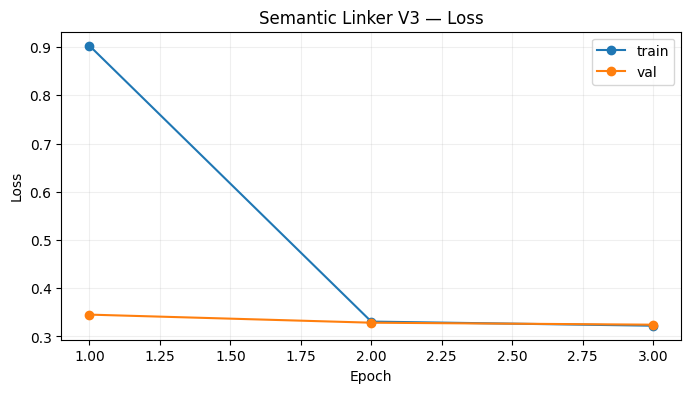

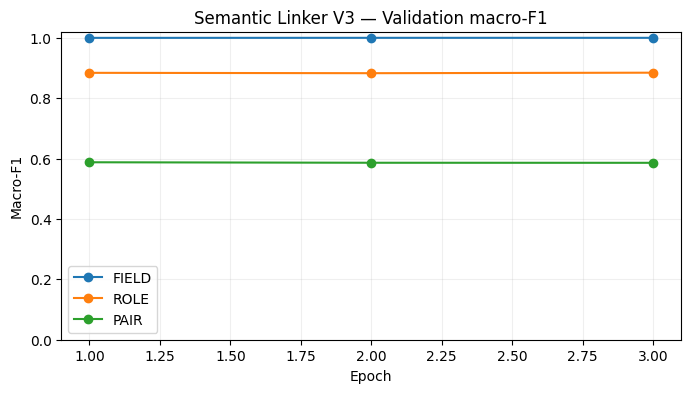

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_df.epoch, history_df.train_loss, marker="o", label="train")
ax.plot(history_df.epoch, history_df.val_loss, marker="o", label="val")
ax.set_title("Semantic Linker V3 — Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=.2)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_df.epoch, history_df.val_field_macro_f1, marker="o", label="FIELD")
ax.plot(history_df.epoch, history_df.val_role_macro_f1, marker="o", label="ROLE")
ax.plot(history_df.epoch, history_df.val_pair_macro_f1, marker="o", label="PAIR")
ax.set_ylim(0, 1.02)
ax.set_title("Semantic Linker V3 — Validation macro-F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.legend()
ax.grid(alpha=.2)
plt.show()


## 14 — Recharger le meilleur checkpoint et analyser VAL

Cette étape précède la calibration. Le TEST reste encore fermé.


In [14]:
best_src = BEST_STATE_PATH if BEST_STATE_PATH.exists() else _find_existing_file(BEST_STATE_PATH.name)
if best_src is None:
    raise FileNotFoundError("Best checkpoint not found.")

unwrap_model(model).load_state_dict(
    torch.load(best_src, map_location=DEVICE)
)
model.to(DEVICE)
model.eval()

val_output = collect_predictions(model, val_loader, desc="VAL best checkpoint")
val_metrics = val_output["metrics"]

print("BEST VALIDATION METRICS")
for k, v in val_metrics.items():
    print(f"{k:24s}: {v:.6f}")

print("\nFIELD report:")
print(classification_report(
    val_output["true_fields"],
    val_output["pred_fields"],
    labels=list(range(NUM_FIELDS)),
    target_names=FIELD_LABELS,
    zero_division=0,
    digits=4,
))

print("\nROLE report:")
print(classification_report(
    val_output["true_roles"],
    val_output["pred_roles"],
    labels=list(range(NUM_ROLES)),
    target_names=ROLE_LABELS,
    zero_division=0,
    digits=4,
))


VAL best checkpoint:   0%|          | 0/960 [00:00<?, ?it/s]

BEST VALIDATION METRICS
loss                    : 0.345279
field_accuracy          : 0.999674
field_macro_f1          : 0.999674
role_accuracy           : 0.872005
role_macro_f1           : 0.883857
pair_accuracy           : 0.871875
pair_macro_f1           : 0.587674
unresolved_recall       : 1.000000
unspecified_role_recall : 0.461123

FIELD report:
                               precision    recall  f1-score   support

requested_usable_capacity_tib     1.0000    1.0000    1.0000      1280
                 client_count     1.0000    1.0000    1.0000      1280
         average_file_size_gb     0.9984    1.0000    0.9992      1280
             max_file_size_gb     1.0000    0.9984    0.9992      1280
             total_file_count     1.0000    1.0000    1.0000      1280
             read_write_ratio     1.0000    1.0000    1.0000      1280
             target_read_gbps     1.0000    0.9977    0.9988      1280
            target_write_gbps     0.9977    1.0000    0.9988      1280
      

## 15 — Calibration hiérarchique sur VAL

La calibration est maintenant en deux étages :

- **FIELD** : seuils par `dimension`, optimisés pour haute précision + rappel de `__UNRESOLVED__`.
- **ROLE** : seuils par FIELD, appliqués seulement lorsque le FIELD est accepté.
  Un ROLE non fiable est abstenu vers `unspecified`, mais le FIELD reste conservé.
- `role_abstained=True` distingue une abstention ROLE d'un véritable label sémantique `unspecified`.

Aucun seuil n'est choisi sur TEST.


In [15]:
def _candidate_thresholds(values, fixed_grid, quantiles=None):
    values = np.asarray(values, dtype=np.float64)
    if values.size == 0:
        return np.asarray([0.0], dtype=np.float64)

    if quantiles is None:
        quantiles = [
            0, .01, .02, .05, .10, .15, .20, .30, .40, .50,
            .60, .70, .80, .85, .90, .92, .94, .95, .96, .97,
            .98, .99, .995, 1.0,
        ]

    qs = np.quantile(values, quantiles)
    merged = np.concatenate([np.asarray(fixed_grid, dtype=float), qs, [0.0]])
    merged = np.clip(merged, 0.0, 0.999999)
    return np.unique(np.round(merged, 6))

def _safe_macro_f1(y_true, y_pred):
    if len(y_true) == 0:
        return float("nan")
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))

# ------------------------------------------------------------------
# FIELD policy
# ------------------------------------------------------------------
def evaluate_field_threshold(output, idx, confidence_threshold, margin_threshold):
    idx = np.asarray(idx, dtype=int)

    TF = output["true_fields"][idx]
    PF = output["pred_fields"][idx]
    FC = output["field_confidence"][idx]
    FM = output["field_margin"][idx]

    raw_resolved = PF != UNRESOLVED_FIELD_ID
    accepted = (
        raw_resolved
        & (FC >= confidence_threshold)
        & (FM >= margin_threshold)
    )

    FF = PF.copy()
    FF[raw_resolved & ~accepted] = UNRESOLVED_FIELD_ID

    accepted_count = int(accepted.sum())
    accepted_precision = (
        float(np.mean(PF[accepted] == TF[accepted]))
        if accepted_count else np.nan
    )

    unresolved_mask = TF == UNRESOLVED_FIELD_ID
    unresolved_recall = (
        float(np.mean(FF[unresolved_mask] == UNRESOLVED_FIELD_ID))
        if unresolved_mask.any() else np.nan
    )

    return {
        "confidence_threshold": float(confidence_threshold),
        "margin_threshold": float(margin_threshold),
        "n": int(len(idx)),
        "accepted_count": accepted_count,
        "accepted_precision": accepted_precision,
        "coverage": float(np.mean(accepted)),
        "unresolved_recall": unresolved_recall,
        "final_field_accuracy": float(np.mean(FF == TF)),
        "final_field_macro_f1": _safe_macro_f1(TF, FF),
    }

def calibrate_field_subset(output, idx, label):
    idx = np.asarray(idx, dtype=int)
    confs = _candidate_thresholds(
        output["field_confidence"][idx],
        np.arange(0.0, 1.0, 0.02),
    )
    margins = _candidate_thresholds(
        output["field_margin"][idx],
        np.arange(0.0, 1.0, 0.025),
    )

    rows = []
    for c in confs:
        for m in margins:
            row = evaluate_field_threshold(output, idx, c, m)
            row["calibration_group"] = label
            rows.append(row)

    grid = pd.DataFrame(rows)
    valid = grid[grid["accepted_count"] > 0].copy()

    eligible = valid[
        (valid["accepted_precision"] >= TARGET_FIELD_ACCEPTED_PRECISION)
        & (
            valid["unresolved_recall"].isna()
            | (valid["unresolved_recall"] >= MIN_UNRESOLVED_FIELD_RECALL)
        )
    ].copy()

    if len(eligible):
        selected = (
            eligible.sort_values(
                ["coverage", "final_field_macro_f1", "accepted_precision"],
                ascending=False,
            ).iloc[0]
        )
        validated = True
    elif len(valid):
        selected = (
            valid.sort_values(
                ["final_field_macro_f1", "accepted_precision", "unresolved_recall", "coverage"],
                ascending=False,
            ).iloc[0]
        )
        validated = False
    else:
        # No resolved predictions in this group.
        selected = pd.Series({
            "confidence_threshold": 0.999999,
            "margin_threshold": 0.999999,
            "n": len(idx),
            "accepted_count": 0,
            "accepted_precision": np.nan,
            "coverage": 0.0,
            "unresolved_recall": 1.0,
            "final_field_accuracy": float(np.mean(output["true_fields"][idx] == UNRESOLVED_FIELD_ID)),
            "final_field_macro_f1": 0.0,
            "calibration_group": label,
        })
        validated = True

    return selected, validated, grid

# Global FIELD fallback.
all_val_idx = np.arange(len(val_output["true_fields"]))
global_field_selected, global_field_validated, global_field_grid = calibrate_field_subset(
    val_output,
    all_val_idx,
    "__GLOBAL__",
)

FIELD_THRESHOLDS_BY_DIMENSION = {}
field_selected_rows = []
field_grid_frames = [global_field_grid]

for dim in sorted(set(val_output["dimensions"].tolist())):
    idx = np.where(val_output["dimensions"] == dim)[0]

    if len(idx) >= MIN_CALIBRATION_SAMPLES:
        selected_dim, validated_dim, grid_dim = calibrate_field_subset(
            val_output,
            idx,
            dim,
        )
        field_grid_frames.append(grid_dim)
    else:
        selected_dim = global_field_selected.copy()
        validated_dim = global_field_validated
        selected_dim["calibration_group"] = dim

    FIELD_THRESHOLDS_BY_DIMENSION[dim] = {
        "confidence_threshold": float(selected_dim["confidence_threshold"]),
        "margin_threshold": float(selected_dim["margin_threshold"]),
        "validated": bool(validated_dim),
        "n": int(len(idx)),
    }

    row = selected_dim.to_dict()
    row["dimension"] = dim
    row["validated"] = bool(validated_dim)
    field_selected_rows.append(row)

field_thresholds_df = pd.DataFrame(field_selected_rows)
field_calibration_grid_df = pd.concat(field_grid_frames, ignore_index=True)

def apply_field_policy(output, thresholds_by_dimension):
    PF = output["pred_fields"].copy()
    FC = output["field_confidence"]
    FM = output["field_margin"]
    dims = output["dimensions"]

    field_accepted = np.zeros(len(PF), dtype=bool)
    FF = PF.copy()

    for i, dim in enumerate(dims):
        fi = int(PF[i])

        # Raw unresolved remains unresolved by definition.
        if fi == UNRESOLVED_FIELD_ID:
            FF[i] = UNRESOLVED_FIELD_ID
            continue

        th = thresholds_by_dimension.get(
            str(dim),
            {
                "confidence_threshold": float(global_field_selected["confidence_threshold"]),
                "margin_threshold": float(global_field_selected["margin_threshold"]),
            },
        )

        ok = (
            FC[i] >= th["confidence_threshold"]
            and FM[i] >= th["margin_threshold"]
        )
        field_accepted[i] = bool(ok)
        if not ok:
            FF[i] = UNRESOLVED_FIELD_ID

    return field_accepted, FF

val_field_accepted, val_final_fields = apply_field_policy(
    val_output,
    FIELD_THRESHOLDS_BY_DIMENSION,
)

# ------------------------------------------------------------------
# ROLE policy
# ------------------------------------------------------------------
def evaluate_role_threshold(output, idx, confidence_threshold, margin_threshold):
    idx = np.asarray(idx, dtype=int)

    TR = output["true_roles"][idx]
    PR = output["pred_roles"][idx]
    RC = output["role_confidence"][idx]
    RM = output["role_margin"][idx]

    pred_specified = PR != UNSPECIFIED_ROLE_ID
    specified_kept = (
        pred_specified
        & (RC >= confidence_threshold)
        & (RM >= margin_threshold)
    )

    FR = PR.copy()
    FR[pred_specified & ~specified_kept] = UNSPECIFIED_ROLE_ID

    specified_count = int(specified_kept.sum())
    specified_precision = (
        float(np.mean(PR[specified_kept] == TR[specified_kept]))
        if specified_count else np.nan
    )

    true_unspecified = TR == UNSPECIFIED_ROLE_ID
    unspecified_recall = (
        float(np.mean(FR[true_unspecified] == UNSPECIFIED_ROLE_ID))
        if true_unspecified.any() else np.nan
    )

    return {
        "confidence_threshold": float(confidence_threshold),
        "margin_threshold": float(margin_threshold),
        "n": int(len(idx)),
        "specified_kept_count": specified_count,
        "specified_precision": specified_precision,
        "specified_coverage": float(np.mean(specified_kept)),
        "unspecified_recall": unspecified_recall,
        "final_role_accuracy": float(np.mean(FR == TR)),
        "final_role_macro_f1": _safe_macro_f1(TR, FR),
    }

def calibrate_role_subset(output, idx, label):
    idx = np.asarray(idx, dtype=int)

    confs = _candidate_thresholds(
        output["role_confidence"][idx],
        np.arange(0.0, 1.0, 0.02),
    )
    margins = _candidate_thresholds(
        output["role_margin"][idx],
        np.arange(0.0, 1.0, 0.025),
    )

    rows = []
    for c in confs:
        for m in margins:
            row = evaluate_role_threshold(output, idx, c, m)
            row["calibration_group"] = label
            rows.append(row)

    grid = pd.DataFrame(rows)
    valid = grid[grid["specified_kept_count"] > 0].copy()

    eligible = valid[
        (valid["specified_precision"] >= TARGET_SPECIFIED_ROLE_PRECISION)
        & (
            valid["unspecified_recall"].isna()
            | (valid["unspecified_recall"] >= MIN_UNSPECIFIED_ROLE_RECALL)
        )
    ].copy()

    if len(eligible):
        selected = (
            eligible.sort_values(
                ["final_role_macro_f1", "final_role_accuracy", "specified_coverage"],
                ascending=False,
            ).iloc[0]
        )
        validated = True
    elif len(valid):
        selected = (
            valid.sort_values(
                ["final_role_macro_f1", "final_role_accuracy", "specified_precision"],
                ascending=False,
            ).iloc[0]
        )
        validated = False
    else:
        # This happens naturally for __UNRESOLVED__, whose only allowed role is unspecified.
        selected = pd.Series({
            "confidence_threshold": 0.999999,
            "margin_threshold": 0.999999,
            "n": len(idx),
            "specified_kept_count": 0,
            "specified_precision": np.nan,
            "specified_coverage": 0.0,
            "unspecified_recall": 1.0,
            "final_role_accuracy": 1.0 if len(idx) else np.nan,
            "final_role_macro_f1": 1.0 if len(idx) else np.nan,
            "calibration_group": label,
        })
        validated = True

    return selected, validated, grid

# Calibrate global role fallback only on FIELD-resolved validation samples.
global_role_idx = np.where(val_field_accepted)[0]
global_role_selected, global_role_validated, global_role_grid = calibrate_role_subset(
    val_output,
    global_role_idx,
    "__GLOBAL__",
)

ROLE_THRESHOLDS_BY_FIELD = {}
role_selected_rows = []
role_grid_frames = [global_role_grid]

for field in FIELD_LABELS:
    fi = FIELD_TO_ID[field]

    if field == "__UNRESOLVED__":
        ROLE_THRESHOLDS_BY_FIELD[field] = {
            "confidence_threshold": 0.999999,
            "margin_threshold": 0.999999,
            "validated": True,
            "n": 0,
        }
        role_selected_rows.append({
            "field": field,
            "confidence_threshold": 0.999999,
            "margin_threshold": 0.999999,
            "validated": True,
            "n": 0,
        })
        continue

    idx = np.where(
        val_field_accepted
        & (val_output["pred_fields"] == fi)
    )[0]

    if len(idx) >= MIN_CALIBRATION_SAMPLES:
        selected_field, validated_field, grid_field = calibrate_role_subset(
            val_output,
            idx,
            field,
        )
        role_grid_frames.append(grid_field)
    else:
        selected_field = global_role_selected.copy()
        validated_field = global_role_validated
        selected_field["calibration_group"] = field

    ROLE_THRESHOLDS_BY_FIELD[field] = {
        "confidence_threshold": float(selected_field["confidence_threshold"]),
        "margin_threshold": float(selected_field["margin_threshold"]),
        "validated": bool(validated_field),
        "n": int(len(idx)),
    }

    row = selected_field.to_dict()
    row["field"] = field
    row["validated"] = bool(validated_field)
    row["n"] = int(len(idx))
    role_selected_rows.append(row)

role_thresholds_df = pd.DataFrame(role_selected_rows)
role_calibration_grid_df = pd.concat(role_grid_frames, ignore_index=True)

def apply_hierarchical_policy(output):
    PF = output["pred_fields"].copy()
    PR = output["pred_roles"].copy()

    field_accepted, FF = apply_field_policy(
        output,
        FIELD_THRESHOLDS_BY_DIMENSION,
    )

    FR = np.full(len(PR), UNSPECIFIED_ROLE_ID, dtype=np.int64)
    role_abstained = np.ones(len(PR), dtype=bool)
    role_preserved = np.zeros(len(PR), dtype=bool)

    for i in range(len(PR)):
        if not field_accepted[i]:
            # FIELD abstention dominates the semantic decision.
            continue

        fi = int(PF[i])
        ri = int(PR[i])
        field_name = ID_TO_FIELD[fi]

        if ri == UNSPECIFIED_ROLE_ID:
            # Legitimate semantic "unspecified", not an abstention.
            FR[i] = UNSPECIFIED_ROLE_ID
            role_abstained[i] = False
            role_preserved[i] = True
            continue

        th = ROLE_THRESHOLDS_BY_FIELD[field_name]
        ok = (
            output["role_confidence"][i] >= th["confidence_threshold"]
            and output["role_margin"][i] >= th["margin_threshold"]
        )

        if ok:
            FR[i] = ri
            role_abstained[i] = False
            role_preserved[i] = True
        else:
            FR[i] = UNSPECIFIED_ROLE_ID
            role_abstained[i] = True

    return {
        "field_accepted": field_accepted,
        "final_fields": FF,
        "final_roles": FR,
        "role_abstained": role_abstained,
        "role_preserved": role_preserved,
    }

def hierarchical_metrics(output):
    policy = apply_hierarchical_policy(output)

    TF = output["true_fields"]
    TR = output["true_roles"]
    PF = output["pred_fields"]
    PR = output["pred_roles"]
    FF = policy["final_fields"]
    FR = policy["final_roles"]
    field_accepted = policy["field_accepted"]
    role_abstained = policy["role_abstained"]

    accepted_count = int(field_accepted.sum())
    field_accepted_precision = (
        float(np.mean(PF[field_accepted] == TF[field_accepted]))
        if accepted_count else np.nan
    )

    unresolved_mask = TF == UNRESOLVED_FIELD_ID
    unspecified_mask = TR == UNSPECIFIED_ROLE_ID

    retained_specified = (
        field_accepted
        & ~role_abstained
        & (FR != UNSPECIFIED_ROLE_ID)
    )
    specified_role_precision = (
        float(np.mean(FR[retained_specified] == TR[retained_specified]))
        if retained_specified.any() else np.nan
    )

    true_pairs = [f"{f}::{r}" for f, r in zip(TF, TR)]
    final_pairs = [f"{f}::{r}" for f, r in zip(FF, FR)]

    return {
        "field_accepted_count": accepted_count,
        "field_accepted_precision": field_accepted_precision,
        "field_coverage": float(np.mean(field_accepted)),
        "unresolved_field_recall": (
            float(np.mean(FF[unresolved_mask] == UNRESOLVED_FIELD_ID))
            if unresolved_mask.any() else np.nan
        ),
        "final_field_accuracy": float(np.mean(FF == TF)),
        "final_field_macro_f1": _safe_macro_f1(TF, FF),
        "role_non_abstained_coverage": float(np.mean(field_accepted & ~role_abstained)),
        "specified_role_precision": specified_role_precision,
        "unspecified_role_recall": (
            float(np.mean(FR[unspecified_mask] == UNSPECIFIED_ROLE_ID))
            if unspecified_mask.any() else np.nan
        ),
        "final_role_accuracy": float(np.mean(FR == TR)),
        "final_role_macro_f1": _safe_macro_f1(TR, FR),
        "final_pair_accuracy": float(np.mean((FF == TF) & (FR == TR))),
        "final_pair_macro_f1": float(
            f1_score(true_pairs, final_pairs, average="macro", zero_division=0)
        ),
    }

val_hierarchical = hierarchical_metrics(val_output)

print("=" * 90)
print("FIELD thresholds by dimension")
print("=" * 90)
display(
    field_thresholds_df[
        [
            "dimension", "n", "confidence_threshold", "margin_threshold",
            "accepted_precision", "coverage", "unresolved_recall",
            "final_field_macro_f1", "validated",
        ]
    ].sort_values("dimension")
)

print("=" * 90)
print("ROLE thresholds by field")
print("=" * 90)
display(
    role_thresholds_df[
        [
            "field", "n", "confidence_threshold", "margin_threshold",
            "specified_precision", "specified_coverage", "unspecified_recall",
            "final_role_macro_f1", "validated",
        ]
    ].sort_values("field")
)

print("=" * 90)
print("VAL — HIERARCHICAL POLICY")
print("=" * 90)
for k, v in val_hierarchical.items():
    print(f"{k:30s}: {v}")


FIELD thresholds by dimension


,dimension,n,confidence_threshold,margin_threshold,accepted_precision,coverage,unresolved_recall,final_field_macro_f1,validated
0,capacity,1570,0.0,0.0,1.000000,0.815287,1.0,1.000000,True
1,file_size,2560,0.0,0.0,0.999219,1.000000,NaN,0.999219,True
2,money,1479,0.0,0.0,1.000000,0.865450,1.0,1.000000,True
3,percent,2560,0.0,0.0,1.000000,1.000000,NaN,1.000000,True
4,power,1570,0.0,0.0,1.000000,0.815287,1.0,1.000000,True
5,throughput,2838,0.0,0.0,0.998828,0.902044,1.0,0.999219,True
6,unknown,2783,0.0,0.0,1.000000,0.919871,1.0,1.000000,True


ROLE thresholds by field


,field,n,confidence_threshold,margin_threshold,specified_precision,specified_coverage,unspecified_recall,final_role_macro_f1,validated
11,__UNRESOLVED__,0,0.999999,0.999999,NaN,NaN,NaN,NaN,True
10,annual_growth_percent,1280,0.000000,0.825000,1.000000,0.125000,1.000000,0.270769,True
2,average_file_size_gb,1282,0.000000,0.875000,1.000000,0.124805,1.000000,0.176822,True
1,client_count,1280,0.000000,0.900000,1.000000,0.125000,1.000000,0.258539,True
8,max_budget_usd,1280,0.866525,0.000000,0.990625,0.500000,0.938776,0.506009,True
3,max_file_size_gb,1278,0.000000,0.800000,1.000000,0.125196,1.000000,0.258944,True
9,max_power_w,1280,0.000000,0.825000,0.996188,0.614844,0.955882,0.614417,True
5,read_write_ratio,1280,0.000000,0.925000,0.988372,0.134375,0.989744,0.283362,True
0,requested_usable_capacity_tib,1280,0.860000,0.000000,0.987988,0.520312,0.918367,0.515979,True
6,target_read_gbps,1277,0.920000,0.000000,0.996173,0.613939,0.962963,0.628515,True


VAL — HIERARCHICAL POLICY
field_accepted_count          : 14080
field_accepted_precision      : 0.9996448863636364
field_coverage                : 0.9166666666666666
unresolved_field_recall       : 1.0
final_field_accuracy          : 0.9996744791666666
final_field_macro_f1          : 0.9996744788189725
role_non_abstained_coverage   : 0.302734375
specified_role_precision      : 0.9952380952380953
unspecified_role_recall       : 0.9920806335493161
final_role_accuracy           : 0.47877604166666665
final_role_macro_f1           : 0.48931965498389074
final_pair_accuracy           : 0.47858072916666666
final_pair_macro_f1           : 0.4718899906980689


## 16 — Diagnostic de calibration VAL + quality gate pré-TEST

On inspecte les seuils FIELD par dimension et ROLE par field, puis on rejoue les probes historiques
(`clents`, `clints`, CPU cores, `alternative_pair`) **avant d'ouvrir TEST**.

Si un probe FIELD critique échoue, le notebook s'arrête ici : le TEST reste intact.


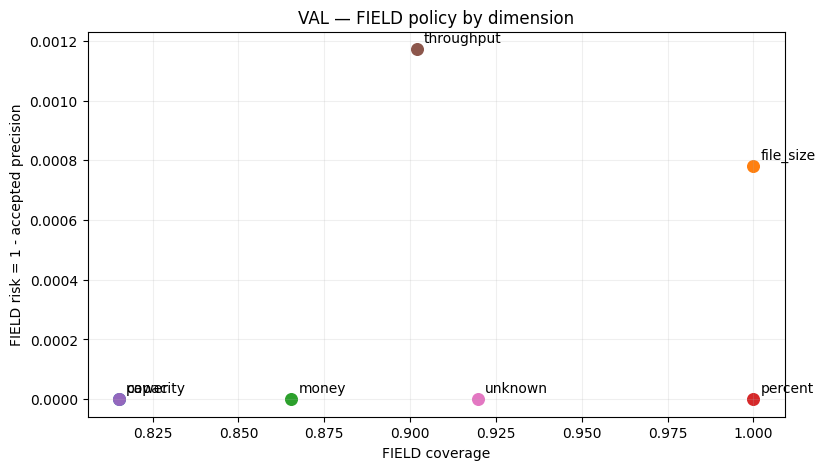

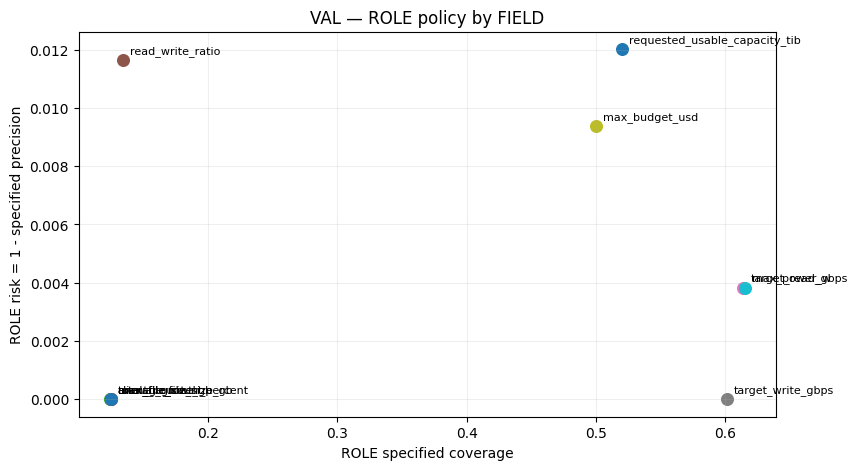

FIELD calibration validated: True
ROLE calibration validated: True


,text,dimension,expected_field,raw_best_field,raw_best_role,field_confidence,field_margin,role_confidence,role_margin,field_accepted,role_abstained,final_field,final_role,field_gate_pass
0,There are [Q]200[/Q] clents.,unknown,client_count,client_count,total_count,0.996277,0.992935,0.944791,0.889583,True,True,client_count,unspecified,True
1,Il y aura [Q]250[/Q] clints sur le système.,unknown,client_count,client_count,total_count,0.999827,0.999769,0.951142,0.902284,True,False,client_count,total_count,True
2,Approximately [Q]260[/Q] noeuds compute will m...,unknown,client_count,client_count,total_count,0.999836,0.999760,0.948917,0.897835,True,True,client_count,unspecified,True
3,"The cluster has [Q]200[/Q] CPU cores, not Lust...",unknown,__UNRESOLVED__,__UNRESOLVED__,unspecified,0.999018,0.998830,1.000000,1.000000,False,True,__UNRESOLVED__,unspecified,True
4,Write throughput could be [Q]20 GB/s[/Q] or 30...,throughput,target_write_gbps,target_write_gbps,current_value,0.980304,0.960661,0.427657,0.106103,True,True,target_write_gbps,unspecified,True
5,Write throughput could be 20 GB/s or [Q]30 GB/...,throughput,target_write_gbps,target_write_gbps,current_value,0.972770,0.945602,0.434266,0.107743,True,True,target_write_gbps,unspecified,True


✅ Critical FIELD diagnostic gate passed


In [16]:
# Compact calibration diagnostics.

field_plot_df = field_thresholds_df.copy()
field_plot_df["risk"] = 1.0 - field_plot_df["accepted_precision"]

fig, ax = plt.subplots(figsize=(9, 5))
for _, row in field_plot_df.iterrows():
    ax.scatter(row["coverage"], row["risk"], s=70)
    ax.annotate(
        str(row["dimension"]),
        (row["coverage"], row["risk"]),
        xytext=(5, 5),
        textcoords="offset points",
    )
ax.set_xlabel("FIELD coverage")
ax.set_ylabel("FIELD risk = 1 - accepted precision")
ax.set_title("VAL — FIELD policy by dimension")
ax.grid(alpha=.2)
plt.show()

role_plot_df = role_thresholds_df[
    role_thresholds_df["field"] != "__UNRESOLVED__"
].copy()
role_plot_df["risk"] = 1.0 - role_plot_df["specified_precision"]

fig, ax = plt.subplots(figsize=(9, 5))
for _, row in role_plot_df.iterrows():
    ax.scatter(row["specified_coverage"], row["risk"], s=70)
    ax.annotate(
        str(row["field"]),
        (row["specified_coverage"], row["risk"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_xlabel("ROLE specified coverage")
ax.set_ylabel("ROLE risk = 1 - specified precision")
ax.set_title("VAL — ROLE policy by FIELD")
ax.grid(alpha=.2)
plt.show()

print("FIELD calibration validated:",
      all(x["validated"] for x in FIELD_THRESHOLDS_BY_DIMENSION.values()))
print("ROLE calibration validated:",
      all(x["validated"] for x in ROLE_THRESHOLDS_BY_FIELD.values()))

# ---------------------------------------------------------
# Pre-TEST critical diagnostic gate
# ---------------------------------------------------------
@torch.no_grad()
def predict_one(marked_text, dimension, model_obj=None, tokenizer_obj=None):
    if dimension not in ALLOWED_FIELDS_BY_DIMENSION:
        raise ValueError(dimension)

    model_obj = model if model_obj is None else model_obj
    tokenizer_obj = tokenizer if tokenizer_obj is None else tokenizer_obj

    enc = tokenizer_obj(
        marked_text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
    )

    model_obj.eval()
    with autocast_context():
        fl, rl = model_obj(
            enc["input_ids"].to(DEVICE),
            enc["attention_mask"].to(DEVICE),
        )

    dec = decode_hierarchical(
        fl.float().cpu(),
        rl.float().cpu(),
        [dimension],
    )

    fi = int(dec["field_ids"][0])
    ri = int(dec["role_ids"][0])

    single_output = {
        "pred_fields": np.asarray([fi]),
        "pred_roles": np.asarray([ri]),
        "field_confidence": dec["field_confidence"],
        "field_margin": dec["field_margin"],
        "role_confidence": dec["role_confidence"],
        "role_margin": dec["role_margin"],
        "dimensions": np.asarray([dimension]),
    }

    policy = apply_hierarchical_policy(single_output)

    final_fi = int(policy["final_fields"][0])
    final_ri = int(policy["final_roles"][0])

    return {
        "raw_best_field": ID_TO_FIELD[fi],
        "raw_best_role": ID_TO_ROLE[ri],
        "field_confidence": float(dec["field_confidence"][0]),
        "field_margin": float(dec["field_margin"][0]),
        "role_confidence": float(dec["role_confidence"][0]),
        "role_margin": float(dec["role_margin"][0]),
        "field_accepted": bool(policy["field_accepted"][0]),
        "role_abstained": bool(policy["role_abstained"][0]),
        "final_field": ID_TO_FIELD[final_fi],
        "final_role": ID_TO_ROLE[final_ri],
    }

diagnostic_examples = [
    {
        "text": "There are [Q]200[/Q] clents.",
        "dimension": "unknown",
        "expected_field": "client_count",
    },
    {
        "text": "Il y aura [Q]250[/Q] clints sur le système.",
        "dimension": "unknown",
        "expected_field": "client_count",
    },
    {
        "text": "Approximately [Q]260[/Q] noeuds compute will mount Lustre.",
        "dimension": "unknown",
        "expected_field": "client_count",
    },
    {
        "text": "The cluster has [Q]200[/Q] CPU cores, not Lustre clients.",
        "dimension": "unknown",
        "expected_field": "__UNRESOLVED__",
    },
    {
        "text": "Write throughput could be [Q]20 GB/s[/Q] or 30 GB/s.",
        "dimension": "throughput",
        "expected_field": "target_write_gbps",
    },
    {
        "text": "Write throughput could be 20 GB/s or [Q]30 GB/s[/Q].",
        "dimension": "throughput",
        "expected_field": "target_write_gbps",
    },
]

diagnostic_rows = []
for ex in diagnostic_examples:
    pred = predict_one(ex["text"], ex["dimension"])
    passed = pred["final_field"] == ex["expected_field"]
    row = {
        **ex,
        **pred,
        "field_gate_pass": bool(passed),
    }
    diagnostic_rows.append(row)

diagnostic_df = pd.DataFrame(diagnostic_rows)
display(diagnostic_df)

if STRICT_DIAGNOSTIC_GATE:
    failed = diagnostic_df[~diagnostic_df["field_gate_pass"]]
    assert failed.empty, (
        "Critical SemanticLinker FIELD probes failed. "
        "Do not export this checkpoint.\n"
        + failed[["text", "expected_field", "final_field"]].to_string(index=False)
    )

print("✅ Critical FIELD diagnostic gate passed")



## 16.5 — Export runtime sécurisé AVANT TEST

À ce stade, TRAIN/VAL, calibration et probes critiques sont terminés. **TEST n'a toujours pas été ouvert.**

Cette étape crée immédiatement :
- le runtime XLM-R + heads ;
- les seuils FIELD/ROLE ;
- les fichiers de compatibilité ;
- les métriques VAL et diagnostics ;
- un ZIP de secours ;
- des parties de 400 MB téléchargeables ;
- un smoke test de rechargement réel.

Ainsi, si une cellule TEST ou reporting échoue ensuite, le modèle entraîné et calibré reste récupérable.


In [17]:
# =========================================================
# SAFE PRE-TEST EXPORT
# =========================================================

def sha256_file(path, chunk_size=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def build_manifest(root_dir):
    root_dir = Path(root_dir)
    rows = []
    for p in sorted(root_dir.rglob("*")):
        if p.is_file():
            if p.name == "manifest.json":
                continue
            rows.append({
                "path": str(p.relative_to(root_dir)),
                "size_bytes": int(p.stat().st_size),
                "sha256": sha256_file(p),
            })
    return rows


def make_fast_zip(src_dir, zip_path):
    """
    ZIP_STORED: no useless compression on safetensors.
    This makes archive creation much faster and keeps it directly extractable.
    """
    src_dir = Path(src_dir)
    zip_path = Path(zip_path)
    if zip_path.exists():
        zip_path.unlink()

    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as zf:
        for p in sorted(src_dir.rglob("*")):
            if p.is_file():
                zf.write(p, arcname=str(p.relative_to(src_dir)))
    return zip_path


def split_file(path, part_size_mb=400):
    """
    Create .part001, .part002, ... to make Kaggle downloads reliable.
    Existing parts with the same prefix are removed first.
    """
    path = Path(path)
    for old in path.parent.glob(path.name + ".part*"):
        old.unlink()

    part_size = int(part_size_mb * 1024 * 1024)
    parts = []

    with open(path, "rb") as src:
        idx = 1
        while True:
            chunk = src.read(part_size)
            if not chunk:
                break
            out = path.parent / f"{path.name}.part{idx:03d}"
            with open(out, "wb") as dst:
                dst.write(chunk)
            parts.append(out)
            idx += 1

    return parts


def write_part_checksums(parts, output_path):
    lines = []
    for p in parts:
        lines.append(f"{sha256_file(p)}  {p.name}")
    Path(output_path).write_text("\n".join(lines) + "\n", encoding="utf-8")


# Fresh directory for the runtime artifact.
if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

core = unwrap_model(model)

# ---------------------------------------------------------
# Runtime model
# ---------------------------------------------------------
core.encoder.save_pretrained(
    EXPORT_DIR / "encoder",
    safe_serialization=True,
)
tokenizer.save_pretrained(EXPORT_DIR / "tokenizer")

torch.save(
    {
        "field_head": core.field_head.state_dict(),
        "role_head": core.role_head.state_dict(),
        "dropout": DROPOUT,
        "hidden_size": core.encoder.config.hidden_size,
        "num_fields": NUM_FIELDS,
        "num_roles": NUM_ROLES,
    },
    EXPORT_DIR / "classifier_heads.pt",
)

(EXPORT_DIR / "labels.json").write_text(
    json.dumps(
        {
            "field_labels": FIELD_LABELS,
            "role_labels": ROLE_LABELS,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

(EXPORT_DIR / "compatibility.json").write_text(
    json.dumps(
        {
            "allowed_fields_by_dimension": {
                k: sorted(v)
                for k, v in ALLOWED_FIELDS_BY_DIMENSION.items()
            },
            "allowed_roles_by_field": {
                k: sorted(v)
                for k, v in ALLOWED_ROLES_BY_FIELD.items()
            },
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

decision_policy = {
    "policy_version": "semantic_linker_v3_2_hierarchical",
    "decoder": "FIELD_then_ROLE",
    "field_thresholds_by_dimension": FIELD_THRESHOLDS_BY_DIMENSION,
    "role_thresholds_by_field": ROLE_THRESHOLDS_BY_FIELD,
    "targets": {
        "field_accepted_precision": TARGET_FIELD_ACCEPTED_PRECISION,
        "minimum_unresolved_field_recall": MIN_UNRESOLVED_FIELD_RECALL,
        "specified_role_precision": TARGET_SPECIFIED_ROLE_PRECISION,
        "minimum_unspecified_role_recall": MIN_UNSPECIFIED_ROLE_RECALL,
    },
    "semantics": {
        "field_rejection": "final_field=__UNRESOLVED__, final_role=unspecified",
        "role_rejection": "keep final_field, final_role=unspecified, role_abstained=true",
        "legitimate_unspecified": "role_abstained=false when raw predicted role is unspecified",
    },
}

(EXPORT_DIR / "thresholds.json").write_text(
    json.dumps(decision_policy, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

training_config = {
    "model_source": MODEL_SOURCE,
    "dataset_version": "semantic_linker_v3_global_stress",
    "semantic_linker_version": "3.2",
    "train_file": TRAIN_FILENAME,
    "val_file": VAL_FILENAME,
    "test_file": TEST_FILENAME,
    "train_size": len(train_records),
    "val_size": len(val_records),
    "expected_test_size": EXPECTED_TEST,
    "test_opened_at_export_time": False,
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "max_length_selected_from": ["train", "val"],
    "gpu_count_detected": GPU_COUNT,
    "training_parallelism": "torch.nn.DataParallel" if GPU_COUNT >= 2 else "single_gpu",
    "per_gpu_batch_size": PER_GPU_BATCH_SIZE,
    "batch_size_total": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "effective_batch_size": EFFECTIVE_BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "best_epoch": int(best_epoch),
    "encoder_lr": ENCODER_LR,
    "head_lr": HEAD_LR,
    "weight_decay": WEIGHT_DECAY,
    "warmup_ratio": WARMUP_RATIO,
    "dropout": DROPOUT,
    "amp": USE_AMP,
    "gradient_checkpointing": USE_GRADIENT_CHECKPOINTING,
    "role_class_weights_enabled": USE_ROLE_CLASS_WEIGHTS,
    "role_label_smoothing": ROLE_LABEL_SMOOTHING,
    "role_class_weights": {
        ROLE_LABELS[i]: float(role_weights_np[i])
        for i in range(NUM_ROLES)
    },
    "special_tokens": SPECIAL_TOKENS,
}

(EXPORT_DIR / "training_config.json").write_text(
    json.dumps(training_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# ---------------------------------------------------------
# VAL / calibration / diagnostics only
# ---------------------------------------------------------
(EXPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(
        {
            "raw_hierarchical_decode": {
                k: float(v) for k, v in val_metrics.items()
            },
            "final_hierarchical_policy": {
                k: (
                    int(v) if isinstance(v, (int, np.integer))
                    else float(v)
                )
                for k, v in val_hierarchical.items()
            },
        },
        indent=2,
    ),
    encoding="utf-8",
)

(EXPORT_DIR / "diagnostic_probes.json").write_text(
    diagnostic_df.to_json(
        orient="records",
        force_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

(EXPORT_DIR / "training_history.json").write_text(
    json.dumps(history, indent=2),
    encoding="utf-8",
)

field_calibration_grid_df.to_csv(
    EXPORT_DIR / "validation_field_threshold_grid.csv",
    index=False,
)
role_calibration_grid_df.to_csv(
    EXPORT_DIR / "validation_role_threshold_grid.csv",
    index=False,
)
field_thresholds_df.to_csv(
    EXPORT_DIR / "validation_field_thresholds_selected.csv",
    index=False,
)
role_thresholds_df.to_csv(
    EXPORT_DIR / "validation_role_thresholds_selected.csv",
    index=False,
)

# ---------------------------------------------------------
# REAL runtime reload smoke test BEFORE TEST
# ---------------------------------------------------------
heads = torch.load(
    EXPORT_DIR / "classifier_heads.pt",
    map_location="cpu",
)

fresh_tokenizer = AutoTokenizer.from_pretrained(
    EXPORT_DIR / "tokenizer",
    local_files_only=True,
)

fresh_model = XLMRSemanticLinker(
    str(EXPORT_DIR / "encoder"),
    len(fresh_tokenizer),
    NUM_FIELDS,
    NUM_ROLES,
    heads["dropout"],
    gradient_checkpointing=False,
).to(DEVICE)

fresh_model.field_head.load_state_dict(heads["field_head"])
fresh_model.role_head.load_state_dict(heads["role_head"])
fresh_model.eval()

@torch.no_grad()
def infer_records_raw(model_obj, tokenizer_obj, records):
    texts = [r["marked_text"] for r in records]
    dims = [r["dimension"] for r in records]

    enc = tokenizer_obj(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    with autocast_context():
        fl, rl = model_obj(
            enc["input_ids"].to(DEVICE),
            enc["attention_mask"].to(DEVICE),
        )

    return decode_hierarchical(
        fl.float().cpu(),
        rl.float().cpu(),
        dims,
    )

smoke_records = val_records[:32]
original_raw = infer_records_raw(unwrap_model(model), tokenizer, smoke_records)
fresh_raw = infer_records_raw(fresh_model, fresh_tokenizer, smoke_records)

assert np.array_equal(
    original_raw["field_ids"],
    fresh_raw["field_ids"],
), "Reloaded FIELD predictions differ"

assert np.array_equal(
    original_raw["role_ids"],
    fresh_raw["role_ids"],
), "Reloaded ROLE predictions differ"

for key in [
    "field_confidence",
    "field_margin",
    "role_confidence",
    "role_margin",
]:
    assert np.allclose(
        original_raw[key],
        fresh_raw[key],
        atol=1e-6,
        rtol=1e-6,
    ), f"Reloaded {key} differs"

del fresh_model
gc.collect()
torch.cuda.empty_cache()

print("✅ PRE-TEST runtime reload smoke test passed")

# Manifest is created only after the runtime itself has passed reload.
manifest = build_manifest(EXPORT_DIR)
(EXPORT_DIR / "manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

# ---------------------------------------------------------
# Immediate safe ZIP + split parts
# ---------------------------------------------------------
make_fast_zip(EXPORT_DIR, SAFE_ZIP_PATH)
SAFE_ZIP_PARTS = split_file(SAFE_ZIP_PATH, ZIP_PART_SIZE_MB)
SAFE_CHECKSUM_PATH = SAFE_ZIP_PATH.with_suffix(SAFE_ZIP_PATH.suffix + ".parts.sha256.txt")
write_part_checksums(SAFE_ZIP_PARTS, SAFE_CHECKSUM_PATH)

print("\n" + "=" * 88)
print("✅ SAFE RUNTIME CREATED BEFORE TEST")
print("=" * 88)
print("ZIP:", SAFE_ZIP_PATH)
print(f"ZIP size: {SAFE_ZIP_PATH.stat().st_size / 1024**2:.2f} MB")
print("Parts:")
for p in SAFE_ZIP_PARTS:
    print(f" - {p.name}: {p.stat().st_size / 1024**2:.2f} MB")
print("Checksums:", SAFE_CHECKSUM_PATH)
print("\nIf any later TEST/reporting cell fails, this PRE-TEST runtime is already recoverable.")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ PRE-TEST runtime reload smoke test passed

✅ SAFE RUNTIME CREATED BEFORE TEST
ZIP: /kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip
ZIP size: 1085.43 MB
Parts:
 - semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part001: 400.00 MB
 - semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part002: 400.00 MB
 - semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part003: 285.43 MB
Checksums: /kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.parts.sha256.txt

If any later TEST/reporting cell fails, this PRE-TEST runtime is already recoverable.


In [18]:
from IPython.display import FileLink, display

print("PRE-TEST recovery downloads:")
for p in SAFE_ZIP_PARTS:
    display(FileLink(str(p)))
display(FileLink(str(SAFE_CHECKSUM_PATH)))

print("\nCompact best checkpoint (optional recovery):")
display(FileLink(str(BEST_STATE_PATH)))


PRE-TEST recovery downloads:


/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part001

/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part002

/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part003

/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.parts.sha256.txt


Compact best checkpoint (optional recovery):


/kaggle/working/semantic_linker_xlmr_v3_2_final/best_checkpoint/semantic_linker_v3_2_best_state.pt

# 17 — TEST final : première ouverture réelle

À partir de cette cellule seulement :
- le fichier TEST est ouvert ;
- ses contrats et overlaps avec TRAIN/VAL sont audités ;
- `MAX_LENGTH` est **vérifié mais jamais retuné** ;
- les métriques finales sont calculées une seule fois.

Toute modification d'hyperparamètre après cette section invaliderait le holdout.


In [19]:
# =========================================================
# FIRST REAL OPENING OF TEST
# =========================================================
test_records = load_jsonl(TEST_PATH)
assert len(test_records) == EXPECTED_TEST, (len(test_records), EXPECTED_TEST)
validate_record_contracts("test", test_records)

# Taxonomy contracts now checked on TEST without changing any hyperparameter.
for i, r in enumerate(test_records):
    assert r["field"] in FIELD_TO_ID, (i, r["field"])
    assert r["role"] in ROLE_TO_ID, (i, r["role"])
    assert r["dimension"] in ALLOWED_FIELDS_BY_DIMENSION, (i, r["dimension"])
    assert r["field"] in ALLOWED_FIELDS_BY_DIMENSION[r["dimension"]], (i, r)
    assert r["role"] in ALLOWED_ROLES_BY_FIELD[r["field"]], (i, r)

test_sample_set = {r["sample_id"] for r in test_records}
test_group_set = {r["group_id"] for r in test_records}
test_text_set = {r["marked_text"] for r in test_records}

assert len(test_sample_set) == len(test_records), "duplicate sample_id in test"
assert len(test_text_set) == len(test_records), "duplicate marked_text in test"

assert not (sample_sets["train"] & test_sample_set), "sample leakage train/test"
assert not (sample_sets["val"] & test_sample_set), "sample leakage val/test"
assert not (group_sets["train"] & test_group_set), "group leakage train/test"
assert not (group_sets["val"] & test_group_set), "group leakage val/test"
assert not (text_sets["train"] & test_text_set), "marked_text leakage train/test"
assert not (text_sets["val"] & test_text_set), "marked_text leakage val/test"

print("✅ TEST contracts and exact split isolation validated")

# TEST length is audited but MAX_LENGTH is frozen and MUST NOT change.
test_lengths, test_qclose = audit_lengths(
    test_records,
    desc="SEALED TEST token audit",
)

print(
    "TEST token stats:",
    "p99=", int(np.percentile(test_lengths, 99)),
    "max=", int(test_lengths.max()),
    "max [/Q] pos=", int(test_qclose.max()),
    "frozen MAX_LENGTH=", MAX_LENGTH,
)

if int(test_qclose.max()) >= MAX_LENGTH - 2:
    raise RuntimeError(
        "Frozen MAX_LENGTH truncates a TEST target marker. "
        "Do NOT retune on TEST; fix the DEV protocol/dataset and rerun from scratch."
    )

# Template overlap audit, purely diagnostic after all decisions are frozen.
test_fp = {template_fingerprint(r["marked_text"]) for r in test_records}
template_overlap_report_test = {
    "test_unique_fingerprints": len(test_fp),
    "train_test_overlap": len(train_fp & test_fp),
    "val_test_overlap": len(val_fp & test_fp),
    "train_test_overlap_rate": len(train_fp & test_fp) / max(len(test_fp), 1),
    "val_test_overlap_rate": len(val_fp & test_fp) / max(len(test_fp), 1),
}
print("\nTemplate fingerprint audit with TEST:")
print(json.dumps(template_overlap_report_test, indent=2))

# QA / metadata are also deferred until after the system is frozen.
if QA_PATH is not None:
    qa = json.loads(QA_PATH.read_text(encoding="utf-8"))
    print("\nQA status:", qa.get("status"))
    failed = [k for k, v in qa.get("checks", {}).items() if not v.get("pass")]
    if failed:
        raise RuntimeError(f"QA report contains failed checks: {failed}")
    print("✅ QA report: all checks PASS")

if METADATA_PATH is not None:
    v3_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
    print("✅ V3 metadata loaded after freeze")

test_loader = DataLoader(
    SemanticDataset(test_records),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

# One final evaluation.
test_output = collect_predictions(model, test_loader, desc="FINAL TEST")
test_metrics = test_output["metrics"]
test_policy = apply_hierarchical_policy(test_output)
test_hierarchical = hierarchical_metrics(test_output)

print("\nTEST — RAW HIERARCHICAL DECODE")
for k, v in test_metrics.items():
    print(f"{k:28s}: {v:.6f}")

print("\nTEST — FINAL HIERARCHICAL POLICY")
for k, v in test_hierarchical.items():
    print(f"{k:30s}: {v}")

print("\nFIELD report:")
print(classification_report(
    test_output["true_fields"],
    test_output["pred_fields"],
    labels=list(range(NUM_FIELDS)),
    target_names=FIELD_LABELS,
    zero_division=0,
    digits=4,
))

print("\nROLE report:")
print(classification_report(
    test_output["true_roles"],
    test_output["pred_roles"],
    labels=list(range(NUM_ROLES)),
    target_names=ROLE_LABELS,
    zero_division=0,
    digits=4,
))


✅ TEST contracts and exact split isolation validated


SEALED TEST token audit:   0%|          | 0/30 [00:00<?, ?it/s]

TEST token stats: p99= 123 max= 132 max [/Q] pos= 108 frozen MAX_LENGTH= 144

Template fingerprint audit with TEST:
{
  "test_unique_fingerprints": 15360,
  "train_test_overlap": 0,
  "val_test_overlap": 0,
  "train_test_overlap_rate": 0.0,
  "val_test_overlap_rate": 0.0
}

QA status: PASS
✅ QA report: all checks PASS
✅ V3 metadata loaded after freeze


FINAL TEST:   0%|          | 0/960 [00:00<?, ?it/s]


TEST — RAW HIERARCHICAL DECODE
loss                        : 0.348342
field_accuracy              : 1.000000
field_macro_f1              : 1.000000
role_accuracy               : 0.866471
role_macro_f1               : 0.878325
pair_accuracy               : 0.866471
pair_macro_f1               : 0.584298
unresolved_recall           : 1.000000
unspecified_role_recall     : 0.455094

TEST — FINAL HIERARCHICAL POLICY
field_accepted_count          : 14080
field_accepted_precision      : 1.0
field_coverage                : 0.9166666666666666
unresolved_field_recall       : 1.0
final_field_accuracy          : 1.0
final_field_macro_f1          : 1.0
role_non_abstained_coverage   : 0.305078125
specified_role_precision      : 0.9937768240343348
unspecified_role_recall       : 0.9897053603123891
final_role_accuracy           : 0.4830078125
final_role_macro_f1           : 0.49088432272107074
final_pair_accuracy           : 0.4830078125
final_pair_macro_f1           : 0.47384975838856913

FIELD rep

## 18 — Confusion matrices TEST


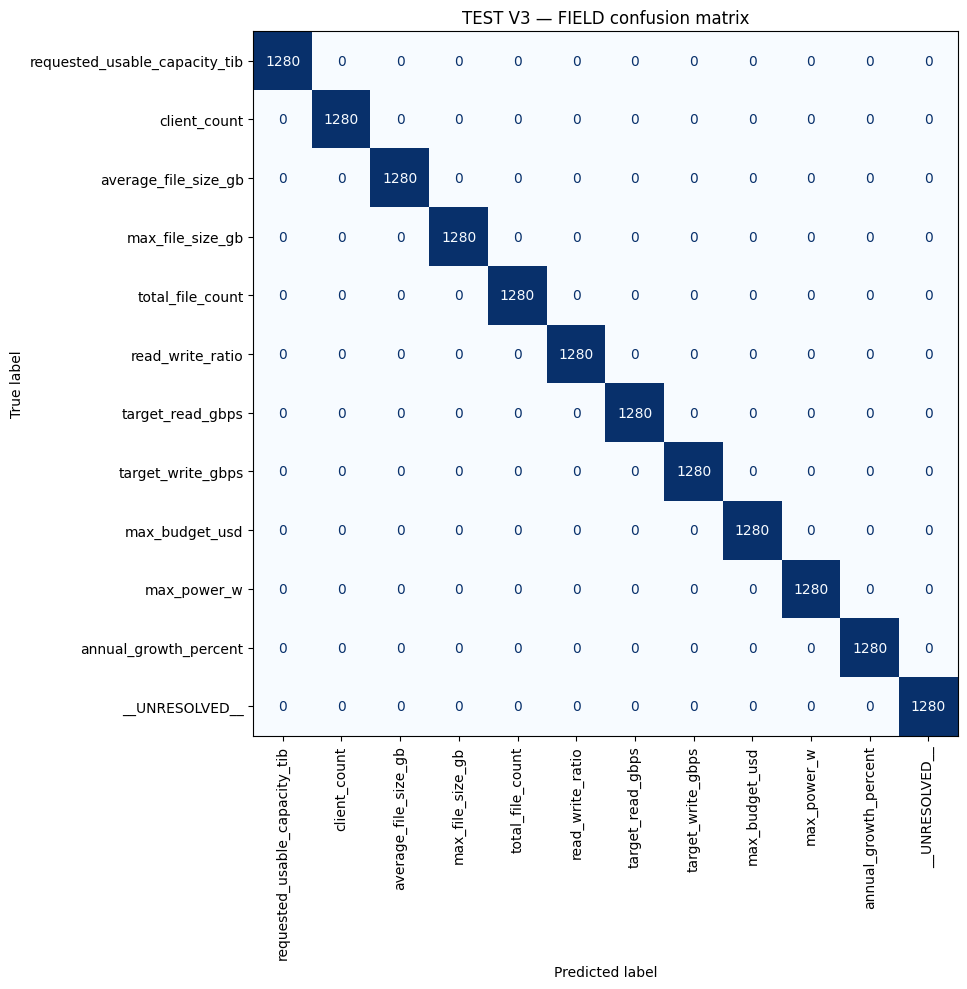

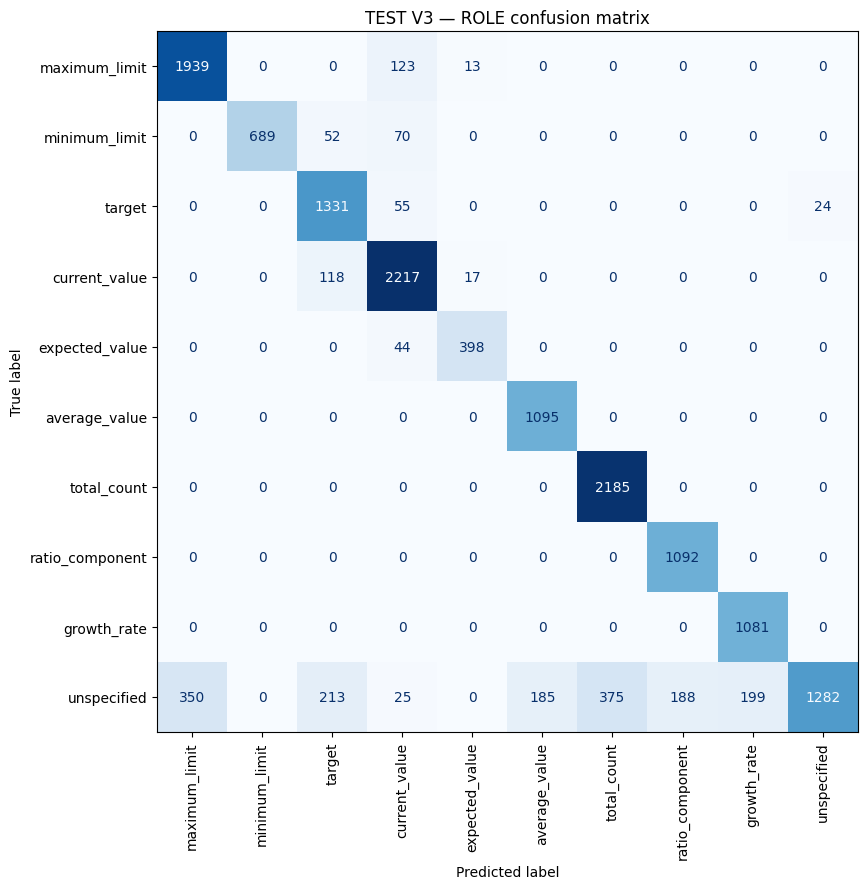

In [20]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    test_output["true_fields"],
    test_output["pred_fields"],
    labels=list(range(NUM_FIELDS)),
    display_labels=FIELD_LABELS,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title("TEST V3 — FIELD confusion matrix")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    test_output["true_roles"],
    test_output["pred_roles"],
    labels=list(range(NUM_ROLES)),
    display_labels=ROLE_LABELS,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title("TEST V3 — ROLE confusion matrix")
plt.tight_layout()
plt.show()


## 19 — Métriques TEST par langue, dimension et famille de stress

Cette section est indispensable pour V3 : une moyenne globale élevée ne suffit pas.

On veut savoir précisément si le modèle résiste à :
- `semantic_anchor_typo`;
- `noisy_mixed_typos`;
- `mixed_code_switch`;
- `hpc_hard_negative`;
- `multi_quantity_collision`;
- `alternative_pair`;
- `quantity_words`;
- etc.


In [21]:
test_field_accepted = test_policy["field_accepted"]
test_final_fields = test_policy["final_fields"]
test_final_roles = test_policy["final_roles"]
test_role_abstained = test_policy["role_abstained"]

def subset_metrics(output, indices):
    idx = np.asarray(indices, dtype=int)

    TF = output["true_fields"][idx]
    TR = output["true_roles"][idx]
    PF = output["pred_fields"][idx]
    PR = output["pred_roles"][idx]

    FA = test_field_accepted[idx]
    FF = test_final_fields[idx]
    FR = test_final_roles[idx]
    RA = test_role_abstained[idx]

    raw_pair_correct = (PF == TF) & (PR == TR)
    final_pair_correct = (FF == TF) & (FR == TR)

    field_accepted_count = int(FA.sum())
    retained_specified = FA & ~RA & (FR != UNSPECIFIED_ROLE_ID)

    unresolved_mask = TF == UNRESOLVED_FIELD_ID
    unspecified_mask = TR == UNSPECIFIED_ROLE_ID

    return {
        "n": int(len(idx)),
        "raw_field_macro_f1": _safe_macro_f1(TF, PF),
        "raw_role_macro_f1": _safe_macro_f1(TR, PR),
        "raw_pair_accuracy": float(np.mean(raw_pair_correct)),
        "field_coverage": float(np.mean(FA)),
        "field_accepted_precision": (
            float(np.mean(PF[FA] == TF[FA]))
            if field_accepted_count else np.nan
        ),
        "final_field_macro_f1": _safe_macro_f1(TF, FF),
        "role_non_abstained_coverage": float(np.mean(FA & ~RA)),
        "specified_role_precision": (
            float(np.mean(FR[retained_specified] == TR[retained_specified]))
            if retained_specified.any() else np.nan
        ),
        "final_role_macro_f1": _safe_macro_f1(TR, FR),
        "final_pair_accuracy": float(np.mean(final_pair_correct)),
        "unresolved_field_recall": (
            float(np.mean(FF[unresolved_mask] == UNRESOLVED_FIELD_ID))
            if unresolved_mask.any() else np.nan
        ),
        "unspecified_role_recall": (
            float(np.mean(FR[unspecified_mask] == UNSPECIFIED_ROLE_ID))
            if unspecified_mask.any() else np.nan
        ),
    }

def grouped_metrics(output, labels):
    rows = []
    labels = np.asarray(labels)
    for label in sorted(set(labels.tolist())):
        idx = np.where(labels == label)[0]
        row = {"group": label}
        row.update(subset_metrics(output, idx))
        rows.append(row)
    return pd.DataFrame(rows)

language_metrics_df = grouped_metrics(
    test_output,
    test_output["languages"],
).rename(columns={"group": "language"})

dimension_metrics_df = grouped_metrics(
    test_output,
    test_output["dimensions"],
).rename(columns={"group": "dimension"})

test_stress = np.asarray([
    s.split("+")[-1] if "+" in s else s
    for s in test_output["sources"]
])

stress_metrics_df = grouped_metrics(
    test_output,
    test_stress,
).rename(columns={"group": "stress_family"})

print("BY LANGUAGE")
display(language_metrics_df)

print("BY DIMENSION")
display(dimension_metrics_df)

print("BY STRESS FAMILY")
display(
    stress_metrics_df.sort_values(
        ["final_pair_accuracy", "raw_pair_accuracy"],
        ascending=True,
    )
)


BY LANGUAGE


,language,n,raw_field_macro_f1,raw_role_macro_f1,raw_pair_accuracy,field_coverage,field_accepted_precision,final_field_macro_f1,role_non_abstained_coverage,specified_role_precision,final_role_macro_f1,final_pair_accuracy,unresolved_field_recall,unspecified_role_recall
0,en,5754,1.0,0.879905,0.869656,0.915885,1.0,1.0,0.304136,0.997701,0.496307,0.484011,1.0,0.996201
1,fr,5786,1.0,0.875605,0.864501,0.917732,1.0,1.0,0.311787,0.992737,0.498506,0.485309,1.0,0.987548
2,mixed,3820,1.0,0.880276,0.864660,0.916230,1.0,1.0,0.296335,0.989381,0.470193,0.478010,1.0,0.983333


BY DIMENSION


,dimension,n,raw_field_macro_f1,raw_role_macro_f1,raw_pair_accuracy,field_coverage,field_accepted_precision,final_field_macro_f1,role_non_abstained_coverage,specified_role_precision,final_role_macro_f1,final_pair_accuracy,unresolved_field_recall,unspecified_role_recall
0,capacity,1574,1.0,0.867078,0.871029,0.813215,1.0,1.0,0.440915,0.980539,0.633843,0.657560,1.0,0.966921
1,file_size,2560,1.0,0.612453,0.849609,1.000000,1.0,1.0,0.125000,1.000000,0.268793,0.275391,NaN,1.000000
2,money,1480,1.0,0.851099,0.866216,0.864865,1.0,1.0,0.431757,0.993740,0.602034,0.631757,1.0,0.986842
3,percent,2560,1.0,0.612152,0.848828,1.000000,1.0,1.0,0.131250,0.997024,0.276518,0.281641,NaN,0.997416
4,power,1568,1.0,0.896255,0.896046,0.816327,1.0,1.0,0.515944,0.990111,0.710486,0.727679,1.0,0.977011
5,throughput,2860,1.0,0.874804,0.881119,0.895105,1.0,1.0,0.547552,0.998723,0.673941,0.695455,1.0,0.995316
6,unknown,2758,1.0,0.717294,0.864032,0.928209,1.0,1.0,0.116751,0.996894,0.318138,0.323785,1.0,0.998255


BY STRESS FAMILY


,stress_family,n,raw_field_macro_f1,raw_role_macro_f1,raw_pair_accuracy,field_coverage,field_accepted_precision,final_field_macro_f1,role_non_abstained_coverage,specified_role_precision,final_role_macro_f1,final_pair_accuracy,unresolved_field_recall,unspecified_role_recall
14,short_telegraphic,960,1.0,0.613500,0.640625,0.916667,1.0,1.0,0.000000,NaN,0.032753,0.195833,1.0,1.000000
0,alternative_pair,960,1.0,0.576005,0.639583,0.916667,1.0,1.0,0.015625,1.000000,0.067078,0.207292,1.0,1.000000
8,multi_quantity_collision,960,1.0,0.901816,0.876042,0.916667,1.0,1.0,0.222917,0.981043,0.358794,0.415625,1.0,0.979592
11,punctuation_case_noise,960,1.0,0.921784,0.907292,0.916667,1.0,1.0,0.259375,0.975904,0.362737,0.422917,1.0,0.964497
12,quantity_words,960,1.0,0.901700,0.883333,0.916667,1.0,1.0,0.234375,0.995556,0.360569,0.432292,1.0,0.994792
15,unit_surface_variation,960,1.0,0.899053,0.883333,0.916667,1.0,1.0,0.269792,0.995885,0.361524,0.438542,1.0,0.994444
3,conversational_human_like,960,1.0,0.880252,0.852083,0.916667,1.0,1.0,0.227083,0.995413,0.360841,0.442708,1.0,0.995215
9,noisy_mixed_typos,960,1.0,0.911522,0.896875,0.916667,1.0,1.0,0.261458,0.996000,0.362022,0.443750,1.0,0.994382
1,clean_natural,960,1.0,0.891609,0.868750,0.916667,1.0,1.0,0.234375,0.995536,0.367152,0.444792,1.0,0.995122
5,hpc_hard_negative,960,1.0,0.906112,0.891667,0.916667,1.0,1.0,0.263542,0.988095,0.370366,0.446875,1.0,0.983607


## 20 — Évaluation spéciale `alternative_pair`

Pour `X or Y`, le Semantic Linker doit surtout fournir correctement **les deux FIELDs**
au composant downstream. V3.2 rapporte séparément :

- exactitude des deux FIELDs ;
- taux des deux FIELDs acceptés et corrects ;
- exactitude des deux couples FIELD+ROLE ;
- disponibilité des deux quantités pour le guard downstream.


In [22]:
alt_idx = np.where(test_stress == "alternative_pair")[0]
assert len(alt_idx) > 0

groups = defaultdict(list)
for i in alt_idx:
    groups[test_output["group_ids"][i]].append(int(i))

bad_group_sizes = {
    gid: len(indices)
    for gid, indices in groups.items()
    if len(indices) != 2
}
assert not bad_group_sizes, list(bad_group_sizes.items())[:10]

raw_both_fields_correct = []
final_both_fields_ready = []
raw_both_full_pairs_correct = []
final_both_full_pairs_retained_and_correct = []
same_gold_field = []

for gid, indices in groups.items():
    idx = np.asarray(indices)

    TF = test_output["true_fields"][idx]
    TR = test_output["true_roles"][idx]
    PF = test_output["pred_fields"][idx]
    PR = test_output["pred_roles"][idx]

    FF = test_final_fields[idx]
    FR = test_final_roles[idx]
    FA = test_field_accepted[idx]
    RA = test_role_abstained[idx]

    same_gold_field.append(len(set(TF.tolist())) == 1)

    raw_both_fields_correct.append(
        bool(np.all(PF == TF))
    )

    # Key metric for the downstream alternative-value resolver/guard.
    final_both_fields_ready.append(
        bool(np.all(FA) and np.all(FF == TF))
    )

    raw_both_full_pairs_correct.append(
        bool(np.all((PF == TF) & (PR == TR)))
    )

    final_both_full_pairs_retained_and_correct.append(
        bool(
            np.all(FA)
            and np.all(~RA)
            and np.all((FF == TF) & (FR == TR))
        )
    )

alternative_pair_metrics = {
    "groups": len(groups),
    "samples": len(alt_idx),
    "all_groups_have_same_gold_field": bool(all(same_gold_field)),
    "raw_both_fields_correct_rate": float(np.mean(raw_both_fields_correct)),
    "final_both_fields_accepted_and_correct_rate": float(np.mean(final_both_fields_ready)),
    "raw_both_full_pairs_correct_rate": float(np.mean(raw_both_full_pairs_correct)),
    "final_both_full_pairs_retained_and_correct_rate": float(
        np.mean(final_both_full_pairs_retained_and_correct)
    ),
}

print(json.dumps(alternative_pair_metrics, indent=2))


{
  "groups": 480,
  "samples": 960,
  "all_groups_have_same_gold_field": true,
  "raw_both_fields_correct_rate": 1.0,
  "final_both_fields_accepted_and_correct_rate": 0.9166666666666666,
  "raw_both_full_pairs_correct_rate": 0.625,
  "final_both_full_pairs_retained_and_correct_rate": 0.0020833333333333333
}


## 21 — Diagnostics TEST (reporting uniquement)

Les probes critiques ont déjà été validées avant l'ouverture du TEST.
Cette section ne sert qu'à rapprocher ces probes des familles de stress TEST.

**Aucun retuning n'est autorisé à partir de ces résultats TEST.**


In [23]:
print("Critical probe gate was executed BEFORE opening TEST.")
display(diagnostic_df)

critical_stress_names = [
    "short_telegraphic",
    "alternative_pair",
]
available = stress_metrics_df[
    stress_metrics_df["stress_family"].isin(critical_stress_names)
]
if len(available):
    display(available)

print("⚠️ TEST diagnostics are reporting-only. Do not retune V3.2 from these results without creating a new untouched holdout.")


Critical probe gate was executed BEFORE opening TEST.


,text,dimension,expected_field,raw_best_field,raw_best_role,field_confidence,field_margin,role_confidence,role_margin,field_accepted,role_abstained,final_field,final_role,field_gate_pass
0,There are [Q]200[/Q] clents.,unknown,client_count,client_count,total_count,0.996277,0.992935,0.944791,0.889583,True,True,client_count,unspecified,True
1,Il y aura [Q]250[/Q] clints sur le système.,unknown,client_count,client_count,total_count,0.999827,0.999769,0.951142,0.902284,True,False,client_count,total_count,True
2,Approximately [Q]260[/Q] noeuds compute will m...,unknown,client_count,client_count,total_count,0.999836,0.999760,0.948917,0.897835,True,True,client_count,unspecified,True
3,"The cluster has [Q]200[/Q] CPU cores, not Lust...",unknown,__UNRESOLVED__,__UNRESOLVED__,unspecified,0.999018,0.998830,1.000000,1.000000,False,True,__UNRESOLVED__,unspecified,True
4,Write throughput could be [Q]20 GB/s[/Q] or 30...,throughput,target_write_gbps,target_write_gbps,current_value,0.980304,0.960661,0.427657,0.106103,True,True,target_write_gbps,unspecified,True
5,Write throughput could be 20 GB/s or [Q]30 GB/...,throughput,target_write_gbps,target_write_gbps,current_value,0.972770,0.945602,0.434266,0.107743,True,True,target_write_gbps,unspecified,True


,stress_family,n,raw_field_macro_f1,raw_role_macro_f1,raw_pair_accuracy,field_coverage,field_accepted_precision,final_field_macro_f1,role_non_abstained_coverage,specified_role_precision,final_role_macro_f1,final_pair_accuracy,unresolved_field_recall,unspecified_role_recall
0,alternative_pair,960,1.0,0.576005,0.639583,0.916667,1.0,1.0,0.015625,1.0,0.067078,0.207292,1.0,1.0
14,short_telegraphic,960,1.0,0.613500,0.640625,0.916667,1.0,1.0,0.000000,NaN,0.032753,0.195833,1.0,1.0


⚠️ TEST diagnostics are reporting-only. Do not retune V3.2 from these results without creating a new untouched holdout.


## 22 — Construire les prédictions TEST traçables

On exporte une ligne par exemple avec :
- gold FIELD/ROLE ;
- raw FIELD/ROLE ;
- confidence/margin ;
- décision sélective ;
- langue ;
- stress family ;
- group_id.

Cela permettra d'analyser V3 localement sans relancer Kaggle.


In [24]:
prediction_rows = []

for i in range(len(test_output["sample_ids"])):
    prediction_rows.append({
        "sample_id": str(test_output["sample_ids"][i]),
        "group_id": str(test_output["group_ids"][i]),
        "language": str(test_output["languages"][i]),
        "dimension": str(test_output["dimensions"][i]),
        "stress_family": str(test_stress[i]),
        "true_field": ID_TO_FIELD[int(test_output["true_fields"][i])],
        "true_role": ID_TO_ROLE[int(test_output["true_roles"][i])],
        "raw_pred_field": ID_TO_FIELD[int(test_output["pred_fields"][i])],
        "raw_pred_role": ID_TO_ROLE[int(test_output["pred_roles"][i])],
        "field_confidence": float(test_output["field_confidence"][i]),
        "field_margin": float(test_output["field_margin"][i]),
        "role_confidence": float(test_output["role_confidence"][i]),
        "role_margin": float(test_output["role_margin"][i]),
        "field_accepted": bool(test_field_accepted[i]),
        "role_abstained": bool(test_role_abstained[i]),
        "final_field": ID_TO_FIELD[int(test_final_fields[i])],
        "final_role": ID_TO_ROLE[int(test_final_roles[i])],
    })

test_predictions_df = pd.DataFrame(prediction_rows)
display(test_predictions_df.head())
print("rows:", len(test_predictions_df))


,sample_id,group_id,language,dimension,stress_family,true_field,true_role,raw_pred_field,raw_pred_role,field_confidence,field_margin,role_confidence,role_margin,field_accepted,role_abstained,final_field,final_role
0,sem_v3_test_0005257,grp_v3_test_04_01_00056,mixed,unknown,paraphrase_synonym,total_file_count,total_count,total_file_count,total_count,0.999819,0.999775,0.875787,0.751574,True,True,total_file_count,unspecified
1,sem_v3_test_0002359,grp_v3_test_01_13_00038,mixed,unknown,quantity_words,client_count,total_count,client_count,total_count,0.999781,0.999673,0.929184,0.858368,True,True,client_count,unspecified
2,sem_v3_test_0012490,grp_v3_test_09_12_00009,en,power,punctuation_case_noise,max_power_w,maximum_limit,max_power_w,maximum_limit,0.999946,0.999891,0.893027,0.787612,True,True,max_power_w,unspecified
3,sem_v3_test_0005086,grp_v3_test_03_15_00045,en,file_size,conversational_human_like,max_file_size_gb,maximum_limit,max_file_size_gb,maximum_limit,0.999957,0.999933,0.869715,0.739429,True,True,max_file_size_gb,unspecified
4,sem_v3_test_0000971,grp_v3_test_00_12_00010,mixed,capacity,punctuation_case_noise,requested_usable_capacity_tib,target,requested_usable_capacity_tib,target,0.999977,0.999953,0.870154,0.744796,True,False,requested_usable_capacity_tib,target


rows: 15360


## 23 — Compléter l'export après TEST

Le runtime a **déjà été exporté et smoke-testé avant TEST**.  
Cette étape ne réentraîne rien et ne réécrit pas les poids : elle ajoute uniquement les métriques TEST, diagnostics finaux et construit l'archive finale téléchargeable.


In [25]:
# =========================================================
# POST-TEST REPORTING ONLY — DO NOT RESAVE MODEL WEIGHTS
# =========================================================

if not (EXPORT_DIR / "encoder").exists():
    raise RuntimeError(
        "PRE-TEST runtime export is missing. "
        "Do not continue: rerun the safe export cell before TEST."
    )

# Mark that final reporting has now observed TEST.
training_config["test_size"] = len(test_records)
training_config["test_opened_at_export_time"] = True
training_config["final_reporting_completed"] = True
(EXPORT_DIR / "training_config.json").write_text(
    json.dumps(training_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

(EXPORT_DIR / "test_metrics.json").write_text(
    json.dumps(
        {
            "raw_hierarchical_decode": {
                k: float(v) for k, v in test_metrics.items()
            },
            "final_hierarchical_policy": {
                k: (
                    int(v) if isinstance(v, (int, np.integer))
                    else float(v)
                )
                for k, v in test_hierarchical.items()
            },
        },
        indent=2,
    ),
    encoding="utf-8",
)

(EXPORT_DIR / "alternative_pair_metrics.json").write_text(
    json.dumps(alternative_pair_metrics, indent=2),
    encoding="utf-8",
)

(EXPORT_DIR / "template_overlap_report.json").write_text(
    json.dumps(
        {
            "train_val": template_overlap_report_dev,
            "test_after_freeze": template_overlap_report_test,
        },
        indent=2,
    ),
    encoding="utf-8",
)

language_metrics_df.to_csv(
    EXPORT_DIR / "test_metrics_by_language.csv",
    index=False,
)
dimension_metrics_df.to_csv(
    EXPORT_DIR / "test_metrics_by_dimension.csv",
    index=False,
)
stress_metrics_df.to_csv(
    EXPORT_DIR / "test_metrics_by_stress_family.csv",
    index=False,
)
test_predictions_df.to_json(
    EXPORT_DIR / "test_predictions.jsonl",
    orient="records",
    lines=True,
    force_ascii=False,
)

# Report plots.
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = field_thresholds_df.copy()
plot_df["risk"] = 1.0 - plot_df["accepted_precision"]
ax.scatter(plot_df["coverage"], plot_df["risk"], s=70)
for _, row in plot_df.iterrows():
    ax.annotate(
        str(row["dimension"]),
        (row["coverage"], row["risk"]),
        xytext=(5, 5),
        textcoords="offset points",
    )
ax.set_xlabel("FIELD coverage")
ax.set_ylabel("FIELD risk")
ax.set_title("Semantic Linker V3.2 — VAL FIELD calibration")
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "validation_field_calibration.png", dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = role_thresholds_df[
    role_thresholds_df["field"] != "__UNRESOLVED__"
].copy()
plot_df["risk"] = 1.0 - plot_df["specified_precision"]
ax.scatter(plot_df["specified_coverage"], plot_df["risk"], s=70)
for _, row in plot_df.iterrows():
    ax.annotate(
        str(row["field"]),
        (row["specified_coverage"], row["risk"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_xlabel("ROLE specified coverage")
ax.set_ylabel("ROLE risk")
ax.set_title("Semantic Linker V3.2 — VAL ROLE calibration")
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "validation_role_calibration.png", dpi=180)
plt.close(fig)

final_summary = {
    "semantic_linker_version": "3.2",
    "training_parallelism": "torch.nn.DataParallel" if GPU_COUNT >= 2 else "single_gpu",
    "gpu_count_detected": int(GPU_COUNT),
    "best_epoch": int(best_epoch),
    "best_val_pair_macro_f1": float(best_val_score),
    "val_pair_macro_f1_raw": float(val_metrics["pair_macro_f1"]),
    "val_final_field_macro_f1": float(val_hierarchical["final_field_macro_f1"]),
    "val_final_role_macro_f1": float(val_hierarchical["final_role_macro_f1"]),
    "val_final_pair_accuracy": float(val_hierarchical["final_pair_accuracy"]),
    "test_field_macro_f1_raw": float(test_metrics["field_macro_f1"]),
    "test_role_macro_f1_raw": float(test_metrics["role_macro_f1"]),
    "test_pair_macro_f1_raw": float(test_metrics["pair_macro_f1"]),
    "test_unresolved_recall_raw": float(test_metrics["unresolved_recall"]),
    "test_unspecified_role_recall_raw": float(test_metrics["unspecified_role_recall"]),
    "test_field_accepted_precision": float(test_hierarchical["field_accepted_precision"]),
    "test_field_coverage": float(test_hierarchical["field_coverage"]),
    "test_final_field_macro_f1": float(test_hierarchical["final_field_macro_f1"]),
    "test_specified_role_precision": float(test_hierarchical["specified_role_precision"]),
    "test_unspecified_role_recall_final": float(test_hierarchical["unspecified_role_recall"]),
    "test_final_role_macro_f1": float(test_hierarchical["final_role_macro_f1"]),
    "test_final_pair_accuracy": float(test_hierarchical["final_pair_accuracy"]),
    "test_final_pair_macro_f1": float(test_hierarchical["final_pair_macro_f1"]),
    "alternative_pair_raw_both_fields_correct": float(
        alternative_pair_metrics["raw_both_fields_correct_rate"]
    ),
    "alternative_pair_final_both_fields_ready": float(
        alternative_pair_metrics["final_both_fields_accepted_and_correct_rate"]
    ),
    "alternative_pair_raw_both_full_pairs_correct": float(
        alternative_pair_metrics["raw_both_full_pairs_correct_rate"]
    ),
    "all_field_thresholds_validated": bool(
        all(x["validated"] for x in FIELD_THRESHOLDS_BY_DIMENSION.values())
    ),
    "all_role_thresholds_validated": bool(
        all(x["validated"] for x in ROLE_THRESHOLDS_BY_FIELD.values())
    ),
    "critical_probe_gate_passed": bool(diagnostic_df["field_gate_pass"].all()),
}

(EXPORT_DIR / "summary.json").write_text(
    json.dumps(final_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Refresh manifest after all TEST reporting files were added.
manifest = build_manifest(EXPORT_DIR)
(EXPORT_DIR / "manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

# Fast final ZIP: STORE, don't waste time recompressing safetensors.
make_fast_zip(EXPORT_DIR, FINAL_ZIP_PATH)
FINAL_ZIP_PARTS = split_file(FINAL_ZIP_PATH, ZIP_PART_SIZE_MB)
FINAL_CHECKSUM_PATH = FINAL_ZIP_PATH.with_suffix(FINAL_ZIP_PATH.suffix + ".parts.sha256.txt")
write_part_checksums(FINAL_ZIP_PARTS, FINAL_CHECKSUM_PATH)

# Small reassembly helper for Windows/macOS/Linux.
REASSEMBLE_SCRIPT_PATH = Path("/kaggle/working/reassemble_semantic_linker_v3_2.py")
REASSEMBLE_SCRIPT_PATH.write_text(
    '''from pathlib import Path
import shutil

base = "semantic_linker_v3_2_FINAL.zip"
parts = sorted(Path(".").glob(base + ".part[0-9][0-9][0-9]"))
if not parts:
    raise SystemExit("No parts found next to this script.")

with open(base, "wb") as out:
    for part in parts:
        print("Adding", part.name)
        with open(part, "rb") as src:
            shutil.copyfileobj(src, out, length=8 * 1024 * 1024)

print("Rebuilt:", base)
''',
    encoding="utf-8",
)

print("\n" + "=" * 90)
print("✅ FINAL V3.2 ARCHIVE CREATED")
print("=" * 90)
print("Runtime directory:", EXPORT_DIR)
print("Final ZIP:", FINAL_ZIP_PATH)
print(f"Final ZIP size: {FINAL_ZIP_PATH.stat().st_size / 1024**2:.2f} MB")
print("Download parts:")
for p in FINAL_ZIP_PARTS:
    print(f" - {p.name}: {p.stat().st_size / 1024**2:.2f} MB")
print("Checksums:", FINAL_CHECKSUM_PATH)
print("Reassembly helper:", REASSEMBLE_SCRIPT_PATH)



✅ FINAL V3.2 ARCHIVE CREATED
Runtime directory: /kaggle/working/semantic_linker_xlmr_v3_2_final/runtime_export
Final ZIP: /kaggle/working/semantic_linker_v3_2_FINAL.zip
Final ZIP size: 1092.89 MB
Download parts:
 - semantic_linker_v3_2_FINAL.zip.part001: 400.00 MB
 - semantic_linker_v3_2_FINAL.zip.part002: 400.00 MB
 - semantic_linker_v3_2_FINAL.zip.part003: 292.89 MB
Checksums: /kaggle/working/semantic_linker_v3_2_FINAL.zip.parts.sha256.txt
Reassembly helper: /kaggle/working/reassemble_semantic_linker_v3_2.py


## 24 — Intégrité finale de l'archive

Le vrai smoke test tokenizer + encoder + heads a déjà été exécuté **avant TEST**.  
Ici, on vérifie uniquement que l'archive finale et toutes ses parties existent et représentent exactement le même nombre d'octets.


In [26]:
required_export_files = [
    EXPORT_DIR / "classifier_heads.pt",
    EXPORT_DIR / "labels.json",
    EXPORT_DIR / "compatibility.json",
    EXPORT_DIR / "thresholds.json",
    EXPORT_DIR / "training_config.json",
    EXPORT_DIR / "validation_metrics.json",
    EXPORT_DIR / "test_metrics.json",
    EXPORT_DIR / "summary.json",
    EXPORT_DIR / "manifest.json",
    EXPORT_DIR / "encoder" / "config.json",
    EXPORT_DIR / "tokenizer" / "tokenizer_config.json",
]

for p in required_export_files:
    assert p.exists(), p

exported_policy = json.loads(
    (EXPORT_DIR / "thresholds.json").read_text(encoding="utf-8")
)
assert exported_policy["policy_version"] == "semantic_linker_v3_2_hierarchical"

assert FINAL_ZIP_PATH.exists()
assert FINAL_ZIP_PARTS
assert all(p.exists() for p in FINAL_ZIP_PARTS)
assert sum(p.stat().st_size for p in FINAL_ZIP_PARTS) == FINAL_ZIP_PATH.stat().st_size
assert FINAL_CHECKSUM_PATH.exists()
assert REASSEMBLE_SCRIPT_PATH.exists()

print("✅ Runtime files present")
print("✅ PRE-TEST reload smoke test was already passed")
print("✅ Final ZIP exists")
print("✅ Split parts reconstruct exactly the final ZIP byte size")
print("✅ SHA256 list exists")
print("✅ Reassembly script exists")


✅ Runtime files present
✅ PRE-TEST reload smoke test was already passed
✅ Final ZIP exists
✅ Split parts reconstruct exactly the final ZIP byte size
✅ SHA256 list exists
✅ Reassembly script exists


## 25 — Résumé final V3.2

Le résumé final est déjà écrit dans `runtime_export/summary.json` avant la création de l'archive.


In [27]:
summary = json.loads(
    (EXPORT_DIR / "summary.json").read_text(encoding="utf-8")
)
summary["safe_pretest_zip"] = str(SAFE_ZIP_PATH)
summary["final_zip"] = str(FINAL_ZIP_PATH)
summary["final_zip_parts"] = [str(p) for p in FINAL_ZIP_PARTS]

print(json.dumps(summary, indent=2))


{
  "semantic_linker_version": "3.2",
  "training_parallelism": "torch.nn.DataParallel",
  "gpu_count_detected": 2,
  "best_epoch": 1,
  "best_val_pair_macro_f1": 0.5876737613066585,
  "val_pair_macro_f1_raw": 0.5876737613066585,
  "val_final_field_macro_f1": 0.9996744788189725,
  "val_final_role_macro_f1": 0.48931965498389074,
  "val_final_pair_accuracy": 0.47858072916666666,
  "test_field_macro_f1_raw": 1.0,
  "test_role_macro_f1_raw": 0.8783254590978313,
  "test_pair_macro_f1_raw": 0.5842978035733563,
  "test_unresolved_recall_raw": 1.0,
  "test_unspecified_role_recall_raw": 0.4550940717074902,
  "test_field_accepted_precision": 1.0,
  "test_field_coverage": 0.9166666666666666,
  "test_final_field_macro_f1": 1.0,
  "test_specified_role_precision": 0.9937768240343348,
  "test_unspecified_role_recall_final": 0.9897053603123891,
  "test_final_role_macro_f1": 0.49088432272107074,
  "test_final_pair_accuracy": 0.4830078125,
  "test_final_pair_macro_f1": 0.47384975838856913,
  "alternativ

# Fichiers finaux à récupérer

Dans **Kaggle → Output**, récupérer en priorité toutes les parties :

`semantic_linker_v3_2_FINAL.zip.part001`, `part002`, etc.

Télécharger également :
- `semantic_linker_v3_2_FINAL.zip.parts.sha256.txt`
- `reassemble_semantic_linker_v3_2.py`

Le ZIP monolithique est aussi laissé dans `/kaggle/working`, mais les parties de 400 MB sont prévues pour éviter le problème de téléchargement rencontré avec V3.


In [28]:
from IPython.display import FileLink, display

print("=" * 90)
print("✅ SEMANTIC LINKER V3.2 FINAL READY")
print("=" * 90)
print("Policy      : hierarchical FIELD → ROLE")
print("GPU mode    :", "T4 x2 / DataParallel" if GPU_COUNT >= 2 else "single GPU")
print("Final ZIP   :", FINAL_ZIP_PATH)
print(f"ZIP size    : {FINAL_ZIP_PATH.stat().st_size / 1024**2:.2f} MB")
print("Parts       :", len(FINAL_ZIP_PARTS))
print("\nDOWNLOAD THESE PARTS:")
for p in FINAL_ZIP_PARTS:
    display(FileLink(str(p)))

print("\nChecksums:")
display(FileLink(str(FINAL_CHECKSUM_PATH)))

print("\nReassembly helper:")
display(FileLink(str(REASSEMBLE_SCRIPT_PATH)))

print("\nOptional monolithic ZIP (if Kaggle/browser accepts the size):")
display(FileLink(str(FINAL_ZIP_PATH)))

print("\nEmergency PRE-TEST runtime (already validated before opening TEST):")
for p in SAFE_ZIP_PARTS:
    display(FileLink(str(p)))


✅ SEMANTIC LINKER V3.2 FINAL READY
Policy      : hierarchical FIELD → ROLE
GPU mode    : T4 x2 / DataParallel
Final ZIP   : /kaggle/working/semantic_linker_v3_2_FINAL.zip
ZIP size    : 1092.89 MB
Parts       : 3

DOWNLOAD THESE PARTS:


/kaggle/working/semantic_linker_v3_2_FINAL.zip.part001

/kaggle/working/semantic_linker_v3_2_FINAL.zip.part002

/kaggle/working/semantic_linker_v3_2_FINAL.zip.part003


Checksums:


...

/kaggle/working/semantic_linker_v3_2_FINAL.zip


Emergency PRE-TEST runtime (already validated before opening TEST):


/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part001

/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part002

/kaggle/working/semantic_linker_v3_2_RUNTIME_SAFE_PRETEST.zip.part003

In [29]:
import os
from pathlib import Path
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

final_zip = Path("semantic_linker_v3_2_FINAL.zip")

assert final_zip.exists(), "❌ Le ZIP final n'existe pas"

size_gb = final_zip.stat().st_size / (1024**3)

print(f"✅ ZIP FINAL trouvé")
print(f"📦 Taille : {size_gb:.2f} GB")
print(f"📍 /kaggle/working/{final_zip.name}")
print("\n👇 Clique sur ce lien pour télécharger directement :\n")

display(FileLink(final_zip.name))

✅ ZIP FINAL trouvé
📦 Taille : 1.07 GB
📍 /kaggle/working/semantic_linker_v3_2_FINAL.zip

👇 Clique sur ce lien pour télécharger directement :



/kaggle/working/semantic_linker_v3_2_FINAL.zip